<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 50px;">Projeto 1 - LabIACD</div>
<div style="text-align: center; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 26px;">Notebook 1 de 3: dados, features e modelos clássicos</div>

O objetivo deste projeto é prever a nota de malignidade (de 1 a 5) de cada nódulo candidato do conjunto de teste do LNDb, do qual só é dada a posição no CT. Os modelos são avaliados pela balanced accuracy, pelo macro F1, pelo QWK e pelo MAE, e a posição final é a média das posições nas quatro métricas. Para treinar, usam-se dois conjuntos: o LIDC-IDRI (1010 pacientes, com até 4 radiologistas por nódulo, lido com o `pylidc`) e os 294 CTs de treino do LNDb (1 a 3 radiologistas, com a malignidade em `chars_trainNodules.csv`). Como o teste é do LNDb e a maior parte dos nódulos de treino vem do LIDC, todas as escolhas são feitas pelas métricas no LNDb.

Para tal, experimentámos 3 abordagens diferentes. Este primeiro notebook trata dos dados e dos modelos clássicos. Começa por recortar um cubo 3D de 48 mm à volta de cada nódulo e por extrair dele cerca de 1130 features com o pyradiomics (secções 2 a 4). Estas secções correm uma só vez e guardam tudo em `data/`. Em seguida, define o pré-processamento, preparação dos dados, o holdout e a validação cruzada (secção 5). Por fim, afina passo a passo seis modelos clássicos e compara-os (secção 6).

O trabalho continua em mais dois notebooks, cada um com conclusões apenas sobre os seus próprios modelos. O notebook 2 (secção 7) usa uma CNN multi-escala. O notebook 3 (secções 9 a 12) é uma segunda versão, que muda a label, a região de onde se extraem as features e a forma de converter as previsões em notas, e gera o `predictions.csv` final. Os outros dois notebooks usam os ficheiros que este cria em `data/`, por isso este tem de correr primeiro. O código partilhado pelos três está em `configuracao.py` e `comum.py`, que têm de estar na mesma pasta que os notebooks.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">1. Configuração</div>
<br>

As importações, a configuração das threads e uma função auxiliar estão no ficheiro `configuracao.py`, partilhado pelos três notebooks, que tem de ser importado antes de tudo o resto. 

In [3]:
# Importações, threads e funções gerais (configuracao.py). Tem de ser a primeira célula a correr.
from configuracao import *

c:\Users\Guilherme\.conda\envs\radiomica\Lib\site-packages\pylidc\__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">2. Preparação dos dados: um cubo 3D por nódulo</div>
<br>

Para cada nódulo, é recortado um cubo com **48 mm** de lado, nele centrado, que é depois reamostrado para **48 × 48 × 48 voxels de 1 mm**. Desta forma, todos os cubos representam o mesmo volume físico, independentemente do espaçamento original de cada CT. Nos nódulos situados junto ao limite do volume, a região em falta é preenchida com −1000 HU, o valor correspondente ao ar.

Os resultados são guardados separadamente para cada CT (`data/por_scan*/`), pelo que, numa nova execução, os CTs já processados não são repetidos.


In [4]:
# =============================================================================================
# 2. FUNÇÕES DE RECORTE: um cubo de 48 mm (48 × 48 × 48 voxels de 1 mm) por nódulo
# =============================================================================================

def recortar(vol, sp, centros, lado_mm=48):
    """Cubos de 48 mm (48³ voxels de 1 mm) centrados em cada ponto (índices de voxel); None se sair do volume."""
    # sp = espaçamento do CT em mm por eixo (ex.: 0,7 × 0,7 × 2,5): 24 mm correspondem a um nº de voxels
    # diferente em cada eixo
    hv = np.ceil(lado_mm / 2 / sp).astype(int) # meio cubo, em voxels, por eixo
    # Margem de ar (−1000 HU) à volta do volume: os nódulos junto à borda também dão um cubo completo
    volp = np.pad(vol, [(x, x) for x in hv], constant_values=-1000) # margem de ar
    cubos = []
    for c in centros: # no volume com margem: de c a c + 2*hv
        p = volp[c[0]:c[0] + 2 * hv[0], c[1]:c[1] + 2 * hv[1], c[2]:c[2] + 2 * hv[2]]
        ok = p.shape == tuple(2 * hv) # False se o centro estiver fora do CT
        # zoom (interpolação linear) leva o bloco para 48³: cada voxel passa a ter 1 mm em todos os eixos
        cubos.append(zoom(p, lado_mm / np.array(p.shape), order=1).astype(np.int16) if ok else None)
    return cubos

def juntar_pasta(pasta):
    """Junta os cubos e as linhas da tabela de todos os CTs de uma pasta (linha i = cubo i)."""
    patches, registos = [], []
    for f in sorted(Path(pasta).glob("*.pkl")): # um ficheiro por CT
        with open(f, "rb") as fh:
            d = pickle.load(fh)
        patches += d["patches"]
        registos += d["registos"]
    return np.stack(patches), pd.DataFrame(registos) # (n, 48, 48, 48) e tabela com n linhas

def gravar(caminho, patches, registos):
    # Cada CT é guardado num ficheiro próprio: se o notebook parar a meio, os CTs já feitos não se repetem
    with open(caminho, "wb") as fh:
        pickle.dump({"patches": patches, "registos": registos}, fh)

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">2.1 LIDC</div>

Os CTs e as anotações do LIDC-IDRI são lidos através da biblioteca `pylidc`, que percorre todos os CTs da sua base de dados. Em cada CT, até quatro radiologistas marcaram os nódulos de forma independente. A função `cluster_annotations` agrupa as marcações que correspondem ao mesmo nódulo, de modo que cada nódulo fica associado às anotações de todos os radiologistas que o identificaram.

Para cada nódulo:
- o **centro** é a média dos centros marcados pelos vários radiologistas, e é a partir dele que se recorta o cubo de 48 mm descrito acima;
- a **label** é a **mediana** das notas de malignidade atribuídas pelos radiologistas;
- são guardados também o número de radiologistas que o anotaram (`n_readers`) e o diâmetro médio anotado (`diameter`). O diâmetro é usado apenas para escolher o raio da esfera na secção 3, e nunca como feature, porque não está disponível no conjunto de teste.

Os nódulos cujo cubo não pode ser recortado, por o CT estar incompleto, são excluídos. Cada CT é guardado num ficheiro próprio em `data/por_scan/`, e a extração completa só é executada se `data/patches.npy` ainda não existir.

In [5]:
# =============================================================================================
# 2.1 LIDC: cubos e labels (via pylidc). Saltada se data/patches.npy já existir.
# =============================================================================================
PASTA_LIDC = Path("data/por_scan")
PASTA_LIDC.mkdir(parents=True, exist_ok=True)


def extrair_scan(scan):
    vol = scan.to_volume(verbose=False) # (linha, coluna, corte), em HU
    sp = np.array([scan.pixel_spacing, scan.pixel_spacing, scan.slice_spacing], dtype=float)
    nodulos = scan.cluster_annotations(verbose=False) # anotações agrupadas por nódulo
    # Centro de cada nódulo = média dos centros marcados pelos vários radiologistas
    centros = [np.mean([a.centroid for a in anns], axis=0).round().astype(int) for anns in nodulos]
    patches, registos = [], []
    for n_id, (anns, cubo) in enumerate(zip(nodulos, recortar(vol, sp, centros))):
        if cubo is None: # CT incompleto
            continue
        patches.append(cubo)
        registos.append({"patient": scan.patient_id, "scan_id": scan.id, "nodule": n_id, "n_readers": len(anns),
                         "malignancy": np.median([a.malignancy for a in anns]), # label: mediana das notas
                         "diameter": np.mean([a.diameter for a in anns])}) # só para escolher o raio (3)
    return patches, registos


if Path("data/patches.npy").exists():
    print("data/patches.npy já existe: extração do LIDC saltada (apagar o ficheiro para refazer)")
else:
    for scan in pl.query(pl.Scan).all(): # todos os CTs da base de dados do pylidc
        ficheiro = PASTA_LIDC / f"{scan.patient_id}_{scan.id}.pkl"
        if ficheiro.exists(): # CT já processado numa execução anterior
            continue
        try:
            gravar(ficheiro, *extrair_scan(scan))
        except Exception as e:
            if "find DICOM files" not in str(e): # pacientes não descarregados
                print(f"{scan.patient_id}: {type(e).__name__}: {e}")
    # Junta todos os CTs num só ficheiro: patches.npy (cubos) e nodulos.csv (uma linha por cubo, mesma ordem)
    patches, nodulos = juntar_pasta(PASTA_LIDC)
    np.save("data/patches.npy", patches)
    nodulos.to_csv("data/nodulos.csv", index=False)
    print(patches.shape)
    del patches # liberta memória

data/patches.npy já existe: extração do LIDC saltada (apagar o ficheiro para refazer)


> Resultado: **2621 nódulos** de 865 pacientes. Destes, 14 têm mais de 4 anotações (nódulos próximos que o `pylidc` agrupou num só) e são excluídos na secção 4, ficando 2607 nódulos do LIDC no dataset final.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">2.2 LNDb: labels</div>

As anotações do LNDb estão distribuídas por três ficheiros:

| Ficheiro | Conteúdo |
|---|---|
| `trainNodules.csv` | uma linha por marcação de cada radiologista (posição e tipo de achado) |
| `chars_trainNodules.csv` | as características atribuídas em cada marcação, incluindo a nota de malignidade |
| `trainNodules_gt.csv` | uma linha por nódulo, já agrupando as marcações dos vários radiologistas |

No LNDb, o identificador `FindingID` é numerado separadamente para cada radiologista: o achado 2 de um radiologista e o achado 2 de outro podem ser nódulos diferentes. Por isso, o `FindingID` não identifica um nódulo por si só. A correspondência é feita através do `trainNodules_gt.csv`: para cada nódulo, as colunas `RadID` e `RadFindingID` indicam que radiologistas o marcaram e com que número. Por exemplo, `RadID = "1,3"` e `RadFindingID = "2,5"` significam que o radiologista 1 o registou como achado 2 e o radiologista 3 como achado 5. Com estes pares, recolhe-se a nota de malignidade dada por cada um dos radiologistas (entre 1 e 3 por nódulo).

A label segue as mesmas regras do LIDC: a **mediana** das notas, com os valores terminados em ,5 arredondados para cima. As notas 0, que significam "não avaliado", são ignoradas. Os achados classificados como não-nódulos são excluídos, porque não têm nota de malignidade. Por fim, só são considerados os nódulos cujo CT está disponível localmente. A tabela resultante é guardada em `data/lndb_nodulos.csv`.

In [6]:
# =============================================================================================
# 2.2 LNDb: labels de malignidade (três ficheiros CSV)
# =============================================================================================
LNDB = Path("LNDb")
CSV = LNDB
nods = pd.read_csv(CSV / "trainset_csv/trainNodules.csv")
chars = pd.read_csv(CSV / "chars_trainNodules.csv")
gt = pd.read_csv(CSV / "trainset_csv/trainNodules_gt.csv")

# malig: série indexada por (CT, radiologista, achado) -> nota de malignidade dessa marcação
chaves = ["LNDbID", "RadID", "FindingID"]
chars[chaves] = chars[chaves].astype(int)
malig = nods.merge(chars, on=chaves, how="left").set_index(chaves)["malignancy"]
malig = malig[~malig.index.duplicated()]


def notas_do_nodulo(l):
    """Malignidade dada por cada radiologista que marcou o nódulo (sem 0 nem vazios)."""
    # RadID e RadFindingID vêm como texto "1,3" / "2,5": o radiologista 1 chamou-lhe achado 2, o 3 chamou-lhe 5
    pares = zip(str(l.RadID).split(","), str(l.RadFindingID).split(","))
    notas = [malig.get((l.LNDbID, int(float(r)), int(float(f)))) for r, f in pares]
    return [n for n in notas if pd.notna(n) and n > 0] # 0 = "não avaliado"


lndb = gt[gt["Nodule"] == 1].copy() # só nódulos (os não-nódulos não têm nota)
lndb["malig_notas"] = [notas_do_nodulo(l) for l in lndb.itertuples()]
lndb["malignancy"] = lndb["malig_notas"].apply(lambda v: np.median(v) if v else np.nan)
lndb["classe"] = np.floor(lndb["malignancy"] + 0.5) # mediana arredondada, ,5 para cima
lndb["patient"] = "LNDb-" + lndb["LNDbID"].astype(int).astype(str).str.zfill(4)
# Só se usam os nódulos cujo CT foi descarregado
ficheiros_ct = {int(p.stem.split("-")[1]): p for p in (LNDB / "data").rglob("LNDb-*.mhd")}
lndb["ct_disponivel"] = lndb["LNDbID"].isin(ficheiros_ct)
lndb.to_csv("data/lndb_nodulos.csv", index=False)
print(lndb["classe"].value_counts().sort_index().to_dict())

{1.0: 127, 2.0: 126, 3.0: 69, 4.0: 26, 5.0: 10}


<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">2.3 LNDb e conjunto de teste: cubos</div>

Nesta secção, os cubos do LNDb são recortados da mesma forma que os do LIDC, com três diferenças: os CTs estão no formato `.mhd` e são lidos com o SimpleITK, já em HU; as posições dos nódulos estão em milímetros e são convertidas para voxels com a geometria de cada CT (o que funciona também nos CTs ligeiramente rodados); e o volume é reordenado para (linha, coluna, corte), a mesma ordem do `pylidc`. A mesma função é usada para recortar os 2900 nódulos candidatos do conjunto de teste (58 CTs).

In [7]:
# =============================================================================================
# 2.3 LNDb (treino) e conjunto de teste: cubos. Saltado se os ficheiros já existirem.
# =============================================================================================

def mm_para_voxel(img, xyz_mm):
    """Posição em mm -> índices (linha, coluna, corte)."""
    # O SimpleITK usa a origem, o espaçamento e a orientação do CT (funciona também nos CTs rodados)
    ix, iy, iz = img.TransformPhysicalPointToContinuousIndex(tuple(float(v) for v in xyz_mm))
    return np.round([iy, ix, iz]).astype(int) # (x, y, z) -> (linha, coluna, corte)


def extrair_ct_lndb(caminho, achados):
    img = sitk.ReadImage(str(caminho)) # .mhd, já em HU
    vol = sitk.GetArrayFromImage(img).transpose(1, 2, 0) # (corte, linha, coluna) -> (linha, coluna, corte)
    sx, sy, sz = img.GetSpacing()
    cubos = recortar(vol, np.array([sy, sx, sz]), [mm_para_voxel(img, (a.x, a.y, a.z)) for a in achados.itertuples()])
    ok = [c is not None for c in cubos]
    # Só ficam os achados com cubo; a tabela guarda o CT e o nº do achado para ligar às labels
    registos = [{"LNDbID": int(a.LNDbID), "FindingID": int(a.FindingID)} for a, k in zip(achados.itertuples(), ok) if k]
    return [c for c in cubos if c is not None], registos


def processar_cts(achados, ficheiros, pasta):
    """Recorta os achados de cada CT e guarda um ficheiro por CT (os já feitos são saltados)."""
    pasta.mkdir(parents=True, exist_ok=True)
    for lndb_id, a in achados.groupby("LNDbID"):
        ficheiro = pasta / f"LNDb-{int(lndb_id):04d}.pkl"
        if ficheiro.exists() or lndb_id not in ficheiros:
            continue
        try:
            gravar(ficheiro, *extrair_ct_lndb(ficheiros[lndb_id], a))
        except Exception as e:
            print(f"LNDb-{int(lndb_id):04d}: {type(e).__name__}: {e}")


# Treino: só os nódulos com nota e com o CT descarregado (saltado se já existir; apagar os ficheiros para refazer)
if not (Path("data/patches_lndb.npy").exists() and Path("data/lndb_cubos.csv").exists()):
    processar_cts(lndb[lndb["malignancy"].notna() & lndb["ct_disponivel"]], ficheiros_ct, Path("data/por_scan_lndb"))
    patches_lndb, reg = juntar_pasta("data/por_scan_lndb")
    cubos_lndb = reg.merge(lndb, on=["LNDbID", "FindingID"], how="left") # junta as labels a cada cubo
    cubos_lndb.insert(0, "idx", range(len(cubos_lndb))) # idx = posição do cubo em patches_lndb
    np.save("data/patches_lndb.npy", patches_lndb)
    cubos_lndb.to_csv("data/lndb_cubos.csv", index=False)

# Teste (o testNodules.csv é copiado para data/, de onde o resto do notebook o lê)
teste = pd.read_csv(CSV / "testNodules.csv")
teste.to_csv("data/testNodules.csv", index=False)
if not (Path("data/patches_teste.npy").exists() and Path("data/teste_cubos.csv").exists()):
    ficheiros_teste = {int(p.stem.split("-")[1]): p for p in (LNDB / "test").rglob("LNDb-*.mhd")}
    processar_cts(teste, ficheiros_teste, Path("data/por_scan_teste"))
    patches_teste, cubos_teste = juntar_pasta("data/por_scan_teste")
    cubos_teste.insert(0, "idx", range(len(cubos_teste)))
    np.save("data/patches_teste.npy", patches_teste)
    cubos_teste.to_csv("data/teste_cubos.csv", index=False)
# mmap_mode="r": lê só o cabeçalho do ficheiro (não carrega os cubos para a memória)
print("LNDb:", np.load("data/patches_lndb.npy", mmap_mode="r").shape,
      "| teste:", np.load("data/patches_teste.npy", mmap_mode="r").shape,
      "| achados sem cubo:", len(teste) - len(pd.read_csv("data/teste_cubos.csv")))

LNDb: (358, 48, 48, 48) | teste: (2895, 48, 48, 48) | achados sem cubo: 5


> resultado: 358 nódulos do LNDb com nota. Numa versão anterior deste trabalho comparou-se o centro de cada cubo com o centro das máscaras dos radiologistas: a distância máxima foi de 0,87 mm (menos de um voxel), o que confirma a conversão de coordenadas, a ordem dos eixos e a orientação dos CTs rodados. No teste, 5 achados do `LNDb-0286` ficam sem cubo (junto à borda do volume) e recebem a nota por defeito.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">2.4 Concordância entre radiologistas: peso de cada nódulo</div>

Mais à frente, cada nódulo recebe um peso que reflete o grau de concordância entre os radiologistas que o avaliaram:

$$\text{peso} = 0{,}5 + \left(1 - \frac{\text{diferença média entre pares de notas}}{4}\right)$$

O peso varia entre 0,5, quando a discordância é máxima (por exemplo, notas 1 e 5), e 1,5, quando todos os radiologistas atribuem a mesma nota. Os nódulos com uma só nota, em que não é possível medir a concordância, recebem o peso mediano dos restantes. Como os pesos são calculados a partir das labels, nunca são usados como features: servem apenas para dar mais ou menos importância a cada nódulo durante o treino.

In [8]:
# =============================================================================================
# 2.4 Peso de cada nódulo pela concordância entre radiologistas (0,5 a 1,5)
# =============================================================================================
nodulos = pd.read_csv("data/nodulos.csv")
if "malig_notas" not in nodulos: # notas de cada radiologista (LIDC)
    # Só na primeira vez: volta a abrir cada CT no pylidc para ler a nota de cada radiologista
    notas = {}
    for scan_id, grupo in nodulos.groupby("scan_id"):
        anns = pl.query(pl.Scan).filter(pl.Scan.id == int(scan_id)).first().cluster_annotations(verbose=False)
        for i, n in grupo.iterrows():
            notas[i] = [int(a.malignancy) for a in anns[int(n.nodule)]]
    nodulos["malig_notas"] = pd.Series(notas)


def peso_concordancia(notas):
    if len(notas) < 2: # uma só nota: sem concordância a medir
        return np.nan
    dif = [abs(a - b) for i, a in enumerate(notas) for b in notas[i + 1:]] # diferença em cada par de notas
    return 0.5 + 1 - np.mean(dif) / 4 # 1,5 se todos iguais; 0,5 se 1 vs 5


cubos_lndb = pd.read_csv("data/lndb_cubos.csv")
for t in (nodulos, cubos_lndb):
    t["malig_notas"] = t["malig_notas"].apply(ler_notas) # texto do CSV -> lista
    t["peso"] = t["malig_notas"].apply(peso_concordancia)
# Os nódulos com uma só nota recebem o peso mediano dos restantes (LIDC + LNDb)
PESO_MEDIANO = pd.concat([nodulos["peso"], cubos_lndb["peso"]]).median()
for t, caminho in ((nodulos, "data/nodulos.csv"), (cubos_lndb, "data/lndb_cubos.csv")):
    t["peso"] = t["peso"].fillna(PESO_MEDIANO)
    t.to_csv(caminho, index=False)

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">3. Features da esfera (pyradiomics)</div>
<br>

A região de análise é a mesma para todos os nódulos e conjuntos: uma **esfera de raio fixo** centrada no cubo, com raio igual ao diâmetro mediano dos nódulos anotados no LIDC e no LNDb (7 mm). Dentro da esfera, consideram-se apenas os voxels acima de **−600 HU**, o que exclui o ar do pulmão e mantém as zonas em vidro despolido. Quando não existe tecido denso suficiente, é usada a esfera inteira, e esse caso fica assinalado na variável `mascara_recurso`. O tamanho anotado pelos radiologistas serve apenas para escolher o raio e nunca é usado como feature.

O pyradiomics extrai 7 classes de features (shape, firstorder, glcm, glrlm, glszm, gldm e ngtdm) na imagem original, em três filtros LoG (σ = 1, 2 e 3 mm) e nas decomposições wavelet, num total de **1130 features** por nódulo, com `binWidth = 25`.

In [9]:
# =============================================================================================
# 3. FEATURES DA ESFERA (pyradiomics): 1130 features por nódulo, numa esfera fixa de 7 mm
# =============================================================================================
# mmap_mode="r": os cubos ficam no disco e só se lê cada um quando é preciso
patches = np.load("data/patches.npy", mmap_mode="r")
patches_lndb = np.load("data/patches_lndb.npy", mmap_mode="r")
patches_teste = np.load("data/patches_teste.npy", mmap_mode="r")
nodulos = pd.read_csv("data/nodulos.csv")
cubos_lndb = pd.read_csv("data/lndb_cubos.csv")

# Raio da esfera = diâmetro mediano dos nódulos anotados (LIDC: diâmetro; LNDb: esfera com o volume anotado)
diametros = pd.concat([nodulos["diameter"], (6 * cubos_lndb["Volume"] / np.pi) ** (1 / 3)])
RAIO_ESFERA = int(round(diametros.median())) # raio = diâmetro mediano: 7 mm
# Distância de cada voxel ao centro do cubo (23,5, entre os voxels 23 e 24) -> esfera booleana
_zz, _yy, _xx = np.mgrid[:48, :48, :48] - 23.5
ESFERA = np.sqrt(_zz ** 2 + _yy ** 2 + _xx ** 2) <= RAIO_ESFERA


def mascara_esfera(cubo):
    """Voxels da esfera mais densos do que o pulmão; se forem menos de 10, a esfera inteira. Devolve (máscara, recurso)."""
    m = ESFERA & (np.asarray(cubo) > -600) # −600 HU: tira o ar, mantém o vidro despolido
    return (ESFERA.copy(), True) if m.sum() < 10 else (m, False)


def features_um_cubo(cubo):
    logging.getLogger("radiomics").setLevel(logging.ERROR) # o pyradiomics escreve muitos avisos
    m, recurso = mascara_esfera(cubo)
    # Extrator: 7 classes de features × (imagem original + LoG de 1, 2 e 3 mm + 8 wavelets)
    ext = featureextractor.RadiomicsFeatureExtractor(binWidth=25) # histogramas com intervalos de 25 HU
    ext.disableAllFeatures()
    for classe in ["shape", "firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm"]:
        ext.enableFeatureClassByName(classe)
    ext.enableImageTypes(Original={}, LoG={"sigma": [1.0, 2.0, 3.0]}, Wavelet={})
    # O pyradiomics trabalha com imagens SimpleITK: cubo e máscara, com voxels de 1 mm
    img = sitk.GetImageFromArray(cubo.astype(np.float32)); img.SetSpacing((1, 1, 1))
    msk = sitk.GetImageFromArray(m.astype(np.uint8)); msk.SetSpacing((1, 1, 1))
    try:
        # Fica só com as features (as chaves "diagnostics_..." são informação sobre a extração)
        f = {k: float(np.real(v)) for k, v in ext.execute(img, msk).items() if not k.startswith("diagnostics")}
    except Exception:
        f = {} # falha: NaN, preenchido pelas medianas (mas em princípio não acontece)
    f["mascara_recurso"] = int(recurso)
    return f


def extrair_features_esfera(cubos, caminho, lote=200):
    """Features de todos os cubos, em paralelo, guardadas a cada lote (retoma onde parou)."""
    caminho = Path(caminho)
    feito = pd.read_csv(caminho) if caminho.exists() else pd.DataFrame() # o que já foi extraído antes
    for a in range(len(feito), len(cubos), lote): # começa no primeiro cubo que falta
        idxs = range(a, min(a + lote, len(cubos)))
        linhas = Parallel(n_jobs=N_JOBS)(delayed(features_um_cubo)(np.asarray(cubos[i])) for i in idxs)
        novo = pd.DataFrame(linhas).assign(idx=list(idxs)) # idx liga ao cubo cubos[i]
        feito = pd.concat([feito, novo], ignore_index=True)
        feito.to_csv(caminho, index=False) # guarda depois de cada lote
    return feito


for nome, cubos in [("lidc", patches), ("lndb", patches_lndb), ("teste", patches_teste)]:
    extrair_features_esfera(cubos, f"data/features_esfera{RAIO_ESFERA}_{nome}.csv")

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">3.1 Visualização da região de análise</div>

Para perceber o que a esfera fixa apanha, a figura mostra o corte axial central de um nódulo ao acaso de cada faixa de tamanho, no LIDC e no LNDb. O tracejado branco é o limite da esfera de 7 mm, e a roxo estão os voxels acima de −600 HU, que são os usados pelo pyradiomics. Nos nódulos pequenos, a região inclui também vasos ou parede que estejam dentro da esfera, e nos maiores apanha só a parte central do nódulo, o que mostra a principal limitação de uma região de tamanho fixo.

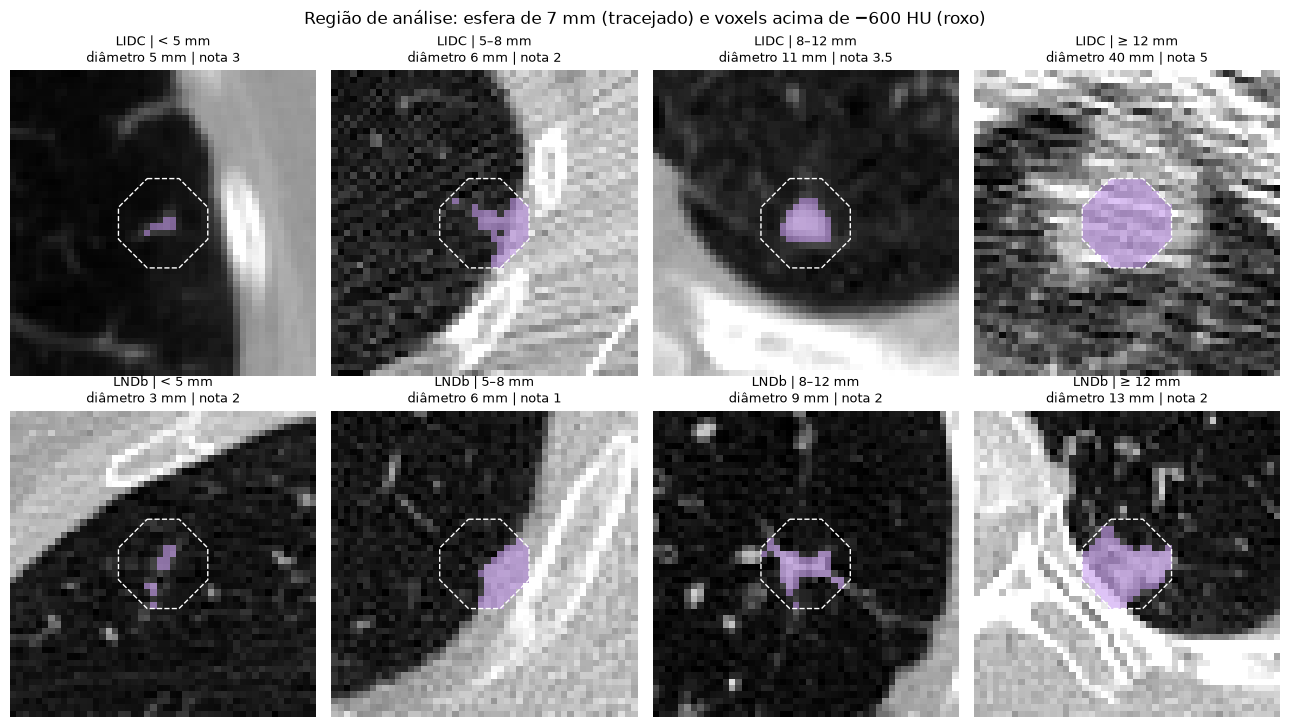

In [10]:
# Visualização da região de análise: corte axial central de um nódulo por faixa de tamanho, no LIDC e no LNDb
# (a roxo: voxels da esfera acima de −600 HU, usados pelo pyradiomics; branco a tracejado: limite da esfera)
from matplotlib.colors import ListedColormap

FAIXAS, ROTULOS = [0, 5, 8, 12, 100], ["< 5 mm", "5–8 mm", "8–12 mm", "≥ 12 mm"]
lndb_i = cubos_lndb.set_index("idx") # linha i = cubo patches_lndb[i]
conjuntos = [("LIDC", patches, nodulos["diameter"], nodulos["malignancy"]),
             ("LNDb", patches_lndb, (6 * lndb_i["Volume"] / np.pi) ** (1 / 3), lndb_i["malignancy"])]
z = 23 # corte junto ao centro do cubo (23,5)

fig, axes = plt.subplots(2, 4, figsize=(13, 7.5))
for linha, (nome, cubos, diam, nota) in zip(axes, conjuntos):
    faixa = pd.cut(diam, FAIXAS, labels=ROTULOS)
    for ax, rot in zip(linha, ROTULOS):
        ax.axis("off")
        cand = diam.index[faixa == rot]
        if len(cand) == 0:
            continue
        i = int(pd.Series(cand).sample(1, random_state=0).iloc[0]) # um nódulo ao acaso desta faixa
        cubo = np.asarray(cubos[i], dtype=np.float32)
        m, recurso = mascara_esfera(cubo)
        ax.imshow(np.clip(cubo[:, :, z], -1000, 400), cmap="gray") # janela de pulmão
        ax.imshow(np.ma.masked_where(~m[:, :, z], m[:, :, z]), cmap=ListedColormap(["#be8aee"]), alpha=0.5)
        ax.contour(ESFERA[:, :, z], levels=[0.5], colors="white", linewidths=1, linestyles="--")
        ax.set_title(f"{nome} | {rot}\ndiâmetro {diam[i]:.0f} mm | nota {nota[i]:g}" + (" | recurso" if recurso else ""),
                     fontsize=9)
fig.suptitle(f"Região de análise: esfera de {RAIO_ESFERA} mm (tracejado) e voxels acima de −600 HU (roxo)")
plt.tight_layout()
plt.show()

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">4. Dataset</div>
<br>

Nesta etapa, a tabela dos nódulos do LIDC e do LNDb é juntada às features da esfera da secção 3, através do `idx`, que indica a posição de cada cubo. O resultado é uma tabela com uma linha por nódulo, com a identificação, a label e as 1130 features.

Saem os 14 nódulos do LIDC com mais de 4 anotações. Como cada CT do LIDC foi lido por no máximo 4 radiologistas, estes casos correspondem a nódulos próximos que o `pylidc` juntou num só. No LIDC, a classe é a mediana das notas, arredondada para cima quando termina em ,5. Assim, na dúvida, o nódulo é tratado como mais suspeito. O diâmetro anotado pelos radiologistas não entra na tabela, porque não existe no conjunto de teste.

In [11]:
%%capture
# =============================================================================================
# 4. DATASET: tabela dos nódulos (LIDC + LNDb) + features da esfera
# =============================================================================================
feats_lidc = pd.read_csv(f"data/features_esfera{RAIO_ESFERA}_lidc.csv").set_index("idx").sort_index()
feats_lndb = pd.read_csv(f"data/features_esfera{RAIO_ESFERA}_lndb.csv").set_index("idx").sort_index()
colunas_id = ["idx", "dataset", "patient", "scan_id", "nodule", "n_readers", "malignancy", "classe"]

# LIDC: idx = posição do cubo em patches.npy; saem os nódulos com mais de 4 anotações (fusões do pylidc)
lidc = pd.read_csv("data/nodulos.csv").join(feats_lidc).rename_axis("idx").reset_index()
lidc = lidc[lidc["n_readers"] <= 4].assign(dataset="LIDC", classe=lambda t: np.floor(t["malignancy"] + 0.5))
# LNDb: as colunas são renomeadas para os nomes do LIDC (scan_id, nodule, n_readers)
lndb = pd.read_csv("data/lndb_cubos.csv").join(feats_lndb, on="idx")
lndb = lndb.assign(dataset="LNDb", scan_id=lndb["LNDbID"], nodule=lndb["FindingID"], n_readers=lndb["AgrLevel"])

# Uma linha por nódulo: identificação + label + 1130 features (o diâmetro dos radiologistas não entra)
dataset_final = pd.concat([t[colunas_id + list(feats_lndb.columns)] for t in (lidc, lndb)], ignore_index=True)
dataset_final["classe"] = dataset_final["classe"].astype(int)
dataset_final.to_csv("data/dataset_final_esfera.csv", index=False)
print(pd.crosstab(dataset_final["dataset"], dataset_final["classe"], normalize="index").round(2))   # % por classe

Desenvolvimento: 2893 nódulos | holdout (LNDb): 72


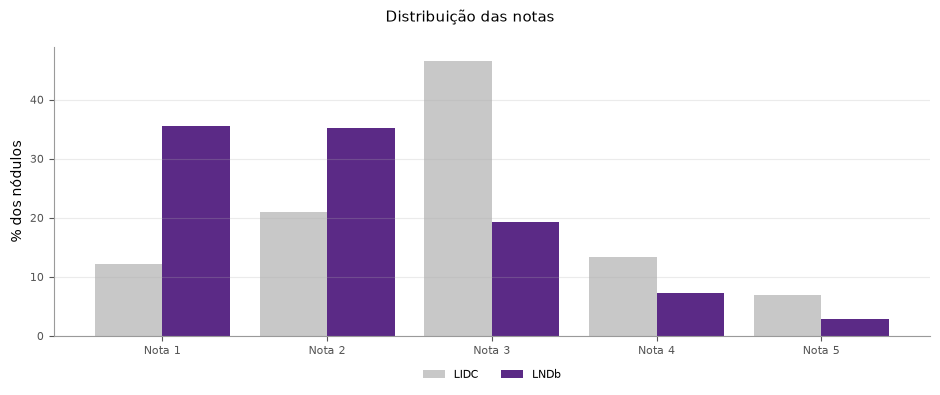

In [12]:
from graficos import distribuicao_notas
distribuicao_notas()

> resultado: As distribuições das notas são muito diferentes: no LIDC domina a nota 3, enquanto no LNDb predominam as notas 1 e 2 e as notas 4 e 5 são raras. Há, portanto, uma diferença de domínio entre os dois datasets e um forte desequilíbrio de classes no LNDb, que é o domínio do conjunto de teste.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">5. Pré-processamento, preparação das features e validação</div>
<br>

Esta secção define a forma como todos os modelos são preparados, treinados e avaliados. Como contém funções usadas também pelos outros notebooks, o código está no ficheiro `comum.py`, carregado na última célula da secção.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">5.1 Pré-processamento (aprendido só no treino de cada fold)</div>

As 1130 features da secção 3 passam por quatro passos antes de entrarem em qualquer modelo:

1. **Imputação:** os valores em falta (casos em que o pyradiomics não conseguiu calcular uma feature) são substituídos pela mediana dessa feature no treino. A variável `mascara_recurso`, que indica os nódulos em que não havia tecido denso suficiente e foi usada a esfera inteira (secção 3), é retirada: é um indicador de como a extração correu, e não uma característica do nódulo.
2. **Remoção das features quase constantes:** saem as features em que um mesmo valor aparece em 95% ou mais dos nódulos, porque não distinguem os nódulos entre si. 
3. **Remoção das features redundantes:** as features são ordenadas da mais para a menos correlacionada com a classe (correlação de Spearman). Percorrendo essa lista, cada feature só é mantida se a sua correlação, em valor absoluto, com todas as features já aceites for inferior a 0,90. Assim, de cada grupo de features muito semelhantes fica apenas a mais informativa. Com estes dois filtros, ficam cerca de 300 das 1130 features. 
4. **Normalização:** cada feature é transformada para média 0 e desvio padrão 1.

Os quatro passos são **aprendidos apenas com os nódulos de treino de cada fold** e depois aplicados, sem alterações, à validação, ao holdout e ao teste. Se as medianas, a seleção ou a normalização fossem calculadas com todos os dados, a informação dos nódulos de validação passaria para o treino e os resultados seriam otimistas.

Como a seleção das features redundantes é o passo mais demorado e se repete muitas vezes com os mesmos folds, o resultado fica guardado em `cache_preprocessamento/`. A chave da cache é calculada a partir do conteúdo do treino (valores, labels e limiares), e por isso uma alteração nos dados obriga automaticamente a um novo cálculo.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">5.2 Dados, holdout e pesos</div>

Os dados são lidos de `data/dataset_final_esfera.csv` (secção 4), que tem uma linha por nódulo do LIDC e do LNDb.

**Holdout:** os pacientes do LNDb são divididos em 5 partes com proporções semelhantes de cada classe (`StratifiedGroupKFold`, com seed fixa). Uma dessas partes, com cerca de 20% dos pacientes, fica reservada como **holdout** e só é usada no fim, para avaliar cada modelo em nódulos que não entraram no treino nem em nenhuma das escolhas feitas ao longo do trabalho. O holdout tem apenas nódulos do LNDb porque o conjunto de teste da competição também é do LNDb. Todos os nódulos do LIDC e os restantes 80% do LNDb formam o desenvolvimento, usado para treinar e comparar os modelos.

**Pesos:** os pesos pela concordância entre radiologistas, calculados na secção 2.4, são apenas lidos nesta fase e guardados à parte, para nunca serem usados como features. O código verifica que nenhum nódulo ficou sem peso. Os pesos só são aplicados nos modelos na secção 6.3, durante o treino.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">5.3 Folds e métricas</div>

Para comparar modelos e configurações sem tocar no holdout, é preciso estimar como cada um se comporta em nódulos que nunca viu, usando apenas o desenvolvimento. Para isso usa-se validação cruzada: os nódulos do desenvolvimento são divididos em 5 folds, e cada modelo é treinado 5 vezes, de cada vez com 4 folds, sendo avaliado no fold que ficou de fora.

A divisão é feita com `StratifiedGroupKFold`, que garante duas coisas. A primeira é que **cada paciente fica num só fold**. Os nódulos do mesmo paciente vêm do mesmo CT e são parecidos entre si, por isso tê-los ao mesmo tempo no treino e na validação sobrestimaria o desempenho. A segunda é que **cada fold tem proporções semelhantes de cada dataset e classe**, o que é importante porque as notas 4 e 5 do LNDb são raras. Para que os resultados não dependam de uma divisão em particular, a validação cruzada é repetida com 3 seeds (42, 7 e 123), pelo que cada avaliação treina 15 modelos.

Os modelos são avaliados com as quatro métricas da competição (balanced accuracy, macro F1, QWK e MAE), calculadas **apenas nos nódulos do LNDb**, que é o domínio do conjunto de teste. Cada nódulo é previsto pelo modelo do fold em que estava na validação, ou seja, por um modelo que não o viu no treino (previsões *out-of-fold*). O resultado final é a média das 3 seeds, com o respetivo desvio padrão.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">5.4 Validação cruzada e ferramentas das experiências</div>

Na secção 6, cada modelo passa por vários passos, e em todos é preciso fazer o mesmo: avaliar uma configuração com a validação cruzada da 5.3 e comparar os resultados. Para não repetir esse código em cada passo, ele está reunido num pequeno conjunto de funções.

A principal é `avaliar`, que treina e avalia um modelo em todos os folds e seeds. Recebe uma função `criar(seed)` que devolve um modelo novo, para que cada fold comece de um modelo por treinar. Em cada fold, o pré-processamento é aprendido só com o treino, e os pesos e o balanceamento são aplicados pelo próprio modelo (6.1), pelo que também só atuam no treino. Os resultados ficam guardados em `cache_avaliacoes/`, por isso uma configuração já avaliada não volta a ser treinada.

A partir dela, a função `tabela` mostra as métricas no LNDb, e o recall de cada classe, de várias configurações lado a lado. A função `pesquisa` testa combinações aleatórias de hiperparâmetros (20 por defeito, com `ParameterSampler`) e escolhe a que tem maior S (bal. acc. + macro F1 + QWK − MAE) no LNDb, salvo indicação em contrário. Os resultados parciais ficam em `cache_tuning/`, por isso uma pesquisa interrompida retoma onde parou.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">5.5 Ferramentas partilhadas pelos modelos</div>

- **Threads:** limitadas a `N_JOBS` na secção 1 (o `HistGradientBoosting` fica mais lento com mais).
- **Regressão com limiares** (`RegressaoComLimiares`, usada pelo GB, LightGBM, SVM e CatBoost): o regressor prevê a mediana contínua das notas e 4 limiares, escolhidos com previsões out-of-fold *dentro do treino* (por paciente) para maximizar o QWK, convertem-na numa nota de 1 a 5.
- **Populações** `POP_DEV` (desenvolvimento) e `POP_TUDO` (desenvolvimento + holdout): o alvo contínuo, os pacientes e os pesos das linhas em que cada modelo final é treinado.
- **Resultados:** `finalizar_modelo` (última célula de cada família) treina o modelo no desenvolvimento e prevê o holdout, treina-o com todos os nódulos e prevê o teste, e guarda tudo em `resultados/<modelo>.pkl` com uma assinatura dos dados (um resultado guardado com outros dados é ignorado, com um aviso).

In [13]:
# Secção 5 (comum.py): pré-processamento, holdout, folds, métricas, validação cruzada e gravação dos resultados.
# Lê data/dataset_final_esfera.csv, criado nas secções 2 a 4.
from comum import *

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">6. Modelos clássicos</div>
<br>

Com os dados, o pré-processamento e a validação definidos, esta secção procura a melhor configuração para seis modelos clássicos: Random Forest, Gradient Boosting, LightGBM, SVM, CatBoost e regressão logística ordinal. Em vez de testar tudo de uma vez, cada modelo é construído aos poucos. Parte-se de um modelo base e, em cada passo, testa-se uma novidade, decidindo se ela melhora o modelo. Os seis modelos passam pelos mesmos passos, pela mesma ordem:

modelo base -> pesos pela concordância -> balanceamento das classes -> peso do LNDb -> hiperparâmetros -> seleção de features -> reavaliação com outras seeds -> modelos finais

A decisão de cada passo fica guardada na configuração do modelo (`CONFIG`) e é usada nos passos seguintes. Para não depender de uma única escolha, cada novidade é testada sobre as **`N_MELHORES` melhores versões** de cada modelo até esse momento (por defeito 2), e não apenas sobre a melhor. Cada uma dessas versões é combinada com cada opção do passo, e seguem em frente as `N_MELHORES` combinações com maior S (bal. acc. + macro F1 + QWK − MAE) no LNDb (função `passo`, definida na 6.1). Por exemplo, o balanceamento (6.4a) é testado com e sem os pesos pela concordância, que são as duas versões que saem da 6.3.

Esta estratégia (*beam search*) é um meio-termo. Seguir apenas a melhor versão em cada passo seria mais rápido, mas podia perder combinações que só funcionam em conjunto, e testar todas as combinações de todos os passos seria demasiado demorado. O preço é que, quanto mais configurações se avaliam, mais otimista tende a ser a escolha final. É para corrigir esse efeito que, no fim, os modelos são reavaliados com outras seeds (6.7).

Em cada passo, as tabelas mostram a melhor versão de cada modelo até esse momento, com as quatro métricas no LNDb (previsões *out-of-fold*, média ± desvio entre as 3 seeds). Cada versão é descrita pelas opções escolhidas até aí: pesos pela concordância (6.3), balanceamento das classes (6.4a), peso dos nódulos do LNDb face aos do LIDC (6.4b) e hiperparâmetros (6.5). Nas tabelas coloridas, o roxo mais escuro e o negrito marcam o melhor valor de cada coluna (no MAE, o mais baixo). Nas tabelas de texto, o negrito marca a versão escolhida. As tabelas com todas as versões testadas são calculadas, mas não são mostradas, por razões de espaço.

In [ ]:
# =============================================================================================
# 6.1 DEFINIÇÃO DOS SEIS MODELOS E DAS SUAS CONFIGURAÇÕES
# =============================================================================================

class HistGBRapido(HistGradientBoostingRegressor):
    """HistGradientBoostingRegressor com a discretização das features feita sem pesos."""
    # O HistGB agrupa cada feature em ≤ 255 intervalos ("bins") antes de treinar. Com pesos, o scikit-learn
    # calcula os intervalos por quantis pesados, o que é ~15× mais lento. Aqui são calculados sem pesos.
    def _binning(self, X, ajustar=False):
        X = np.array(X, dtype=float)
        if ajustar: # no treino: calcula os limites dos intervalos
            perc = np.linspace(0, 100, num=self.max_bins + 1)[1:-1]
            self.arestas_ = []
            for col in X.T:
                col = col[~np.isnan(col)]
                self.arestas_.append(None if len(np.unique(col)) <= self.max_bins else
                                     np.unique(np.percentile(col, perc, method="averaged_inverted_cdf")))
        for j, a in enumerate(self.arestas_): # substitui cada valor pelo nº do intervalo
            if a is not None:
                nan = np.isnan(X[:, j])
                X[:, j] = np.searchsorted(a, X[:, j], side="left")
                X[nan, j] = np.nan
        return X

    def fit(self, X, y, sample_weight=None):
        return super().fit(self._binning(X, ajustar=True), y, sample_weight=sample_weight)

    def predict(self, X):
        return super().predict(self._binning(X))


def pesos_por_classe(y):
    """Peso de cada nódulo inversamente proporcional à frequência da sua classe (o mesmo que class_weight="balanced")."""
    y = np.asarray(y)
    cl = np.unique(y)
    return pd.Series(compute_class_weight("balanced", classes=cl, y=y), index=cl).loc[y].to_numpy()


SAMPLERS = {"smote": lambda: SMOTE(k_neighbors=5, random_state=42), "ros": lambda: RandomOverSampler(random_state=42)}


class Classificador(BaseEstimator):
    """
    Classificador (RF, LogisticIT) com os pesos e o balanceamento aplicados só no fit (só no treino).
    pesos: série pelo índice de X (peso do LNDb x peso pela concordância) ou None;
    balanceamento: None, "classe" (pesos inversos à frequência), "ros" (RandomOverSampler) ou "smote".
    """
    def __init__(self, modelo, pesos=None, balanceamento=None):
        self.modelo, self.pesos, self.balanceamento = modelo, pesos, balanceamento

    def fit(self, X, y):
        y = np.asarray(y)
        w = None if self.pesos is None else self.pesos.loc[X.index].to_numpy()
        if self.balanceamento == "classe":
            # As classes raras pesam mais (multiplica pelos pesos que já existam)
            pc = pesos_por_classe(y)
            w = pc if w is None else pc * w
        elif self.balanceamento in SAMPLERS:
            # Reamostragem: duplica (ROS) ou cria por interpolação (SMOTE) nódulos das classes raras
            sampler = SAMPLERS[self.balanceamento]()
            X, y = sampler.fit_resample(X, y)
            if w is not None:     # ROS: cada cópia leva o peso do original; SMOTE: sintéticos com o peso mediano
                w = (w[sampler.sample_indices_] if hasattr(sampler, "sample_indices_")
                     else np.r_[w, np.full(len(y) - len(w), np.median(w))])
        self.modelo_ = clone(self.modelo)
        self.modelo_.fit(X, y) if w is None else self.modelo_.fit(X, y, sample_weight=w)
        return self

    def predict(self, X):
        return self.modelo_.predict(X)


class RegressaoBalanceada(BaseEstimator):
    """
    Regressão com limiares (5.5) com balanceamento opcional no fit: GB, LightGBM, CatBoost e SVM.
    pesos: série pelo índice de X ou None; balanceamento: None, "classe" (pesos inversos à frequência) ou "ros"
    (RandomOverSampler: cada cópia leva o alvo, o paciente e o peso do original).
    O SMOTE não se aplica: os nódulos sintéticos não têm alvo contínuo nem paciente.
    """
    def __init__(self, regressor, alvo, grupos, pesos=None, balanceamento=None, random_state=42):
        self.regressor, self.alvo, self.grupos, self.pesos = regressor, alvo, grupos, pesos
        self.balanceamento, self.random_state = balanceamento, random_state

    def fit(self, X, y):
        if self.balanceamento is None: # sem balanceamento: diretamente
            self.modelo_ = RegressaoComLimiares(self.regressor, self.alvo, self.grupos, self.pesos).fit(X, y)
            return self
        alvo, g = self.alvo.loc[X.index].to_numpy(), self.grupos.loc[X.index].to_numpy()
        w = None if self.pesos is None else self.pesos.loc[X.index].to_numpy()
        y = np.asarray(y)
        if self.balanceamento == "ros":
            # Duplica nódulos das classes raras; cada cópia leva o alvo, o paciente e o peso do original
            ros = RandomOverSampler(random_state=self.random_state)
            X, y = ros.fit_resample(X, y)
            i = ros.sample_indices_
            alvo, g, w = alvo[i], g[i], None if w is None else w[i]
        elif self.balanceamento == "classe":
            pc = pesos_por_classe(y)
            w = pc if w is None else pc * w
        # Depois do ROS há índices repetidos: cria-se um índice novo e séries alinhadas com ele
        X = pd.DataFrame(np.asarray(X), columns=X.columns) # índice novo 0..n-1
        serie = lambda v: None if v is None else pd.Series(v, index=X.index)
        self.modelo_ = RegressaoComLimiares(self.regressor, serie(alvo), serie(g), serie(w)).fit(X, y)
        return self

    def predict(self, X):
        return self.modelo_.predict(X)


# tipo: "clf" (classificador, envolvido no Classificador) ou "reg" (regressão com limiares, na RegressaoBalanceada)
# params: hiperparâmetros iniciais (alterados na 6.5); novo(params, seed): cria o modelo
MODELOS = {
    "RF": dict(tipo="clf", params=dict(n_estimators=300),
               novo=lambda p, s: RandomForestClassifier(**p, random_state=s, n_jobs=N_JOBS)),
    "GB": dict(tipo="reg", params=dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=20,
                                       l2_regularization=1.0),
               novo=lambda p, s: HistGBRapido(**p, random_state=s)),
    "LightGBM": dict(tipo="reg", params=dict(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=20,
                                             reg_lambda=1.0),
                     novo=lambda p, s: LGBMRegressor(**p, random_state=s, n_jobs=N_JOBS, verbosity=-1)),
    "SVM": dict(tipo="reg", params=dict(C=1.0, gamma="scale", epsilon=0.1),
                novo=lambda p, s: SVR(kernel="rbf", cache_size=500, **p)),
    "CatBoost": dict(tipo="reg", params=dict(iterations=400, learning_rate=0.05, depth=4, l2_leaf_reg=3.0),
                     novo=lambda p, s: CatBoostRegressor(**p, random_seed=s, thread_count=N_JOBS, verbose=0,
                                                         allow_writing_files=False)),
    "LogisticIT": dict(tipo="clf", params=dict(alpha=1.0), novo=lambda p, s: LogisticIT(**p, max_iter=1000)),
}
# CONFIG: a configuração atual de cada modelo. Cada passo da secção 6 testa uma novidade SOBRE a configuração
# atual (a melhor até ao momento) e guarda aqui a decisão, que passa a valer nos passos seguintes:
#   pesos: pesos pela concordância (6.3); bal: balanceamento das classes (6.4a);
#   peso_lndb: peso dos nódulos do LNDb (6.4b); params: hiperparâmetros (6.5)
CONFIG = {m: dict(pesos=False, peso_lndb=1, bal=None, params=dict(M["params"])) for m, M in MODELOS.items()}


def pesos_cfg(pop, cfg):
    """Pesos dos nódulos de 'pop' para uma configuração (peso do LNDb x concordância), ou None se forem todos 1."""
    return pesos_de(pop, cfg["peso_lndb"], cfg["pesos"]) if (cfg["peso_lndb"] != 1 or cfg["pesos"]) else None


def montar(nome, cfg, seed_modelo=False):
    """criar(seed) → modelo novo com uma configuração (pesos, balanceamento e hiperparâmetros)."""
    M = MODELOS[nome]
    sem = (lambda s: s) if seed_modelo else (lambda s: 42) # seed do modelo: a da repetição ou 42
    w = pesos_cfg(POP_DEV, cfg)
    if M["tipo"] == "clf":
        return lambda s: Classificador(M["novo"](cfg["params"], sem(s)), w, cfg["bal"])
    return lambda s: RegressaoBalanceada(M["novo"](cfg["params"], sem(s)), df["malignancy"], grupos, w, cfg["bal"], s)


def correr_cfg(nome, cfg, seeds=SEEDS, seed_modelo=False, selecao=True):
    """Avalia um modelo com uma configuração completa. Devolve (métricas por fold, oof) e guarda o score."""
    # chave: identifica a configuração na cache (cache_avaliacoes/)
    res, oof = avaliar(montar(nome, cfg, seed_modelo), seeds=seeds, selecao=selecao,
                       chave=("correr", nome, repr(cfg), seed_modelo))
    if seeds == SEEDS and not seed_modelo and selecao: # só as avaliações comparáveis entre si entram no ranking
        r = resumo_lndb(oof)["média"]
        SCORE[(nome, repr(cfg))] = r["bal_acc"] + r["macro_f1"] + r["qwk"] - r["mae"]
    return res, oof


def correr(nome, mudancas=None, seeds=SEEDS, seed_modelo=False, selecao=True):
    """Avalia um modelo com a sua melhor configuração atual (mais as 'mudancas'). Devolve (métricas por fold, oof)."""
    return correr_cfg(nome, {**CONFIG[nome], **(mudancas or {})}, seeds, seed_modelo, selecao)


# ---------------------------------------------------------------------------------------------
# Seleção com as N melhores versões ("beam search"): em cada passo, cada uma das N_MELHORES versões de cada
# modelo é combinada com cada opção da novidade, e ficam as N_MELHORES
# ---------------------------------------------------------------------------------------------
N_MELHORES = 2 # 2 ou 3 (3 = mais combinações e mais tempo)
SCORE = {} # (modelo, configuração) -> S (bal. acc. + macro F1 + QWK − MAE) no LNDb
CANDIDATOS = {m: [CONFIG[m]] for m in MODELOS} # versões de cada modelo em jogo (começa no modelo base)


def descrever(cfg):
    """Descrição curta de uma configuração (para as tabelas)."""
    return f"pesos {'sim' if cfg['pesos'] else 'não'} | bal {cfg['bal']} | LNDb x{cfg['peso_lndb']}"


def mostrar_candidatos():
    print(f"Versões que passam ao passo seguinte (as {N_MELHORES} melhores de cada modelo, por S (bal. acc. + macro F1 + QWK - MAE)):")
    display(pd.DataFrame([{"modelo": m, "posição": i + 1, "configuração": descrever(c),
                           "S": round(SCORE[(m, repr(c))], 3)}
                          for m in MODELOS for i, c in enumerate(CANDIDATOS[m])]).set_index(["modelo", "posição"]))


def passo(campo, opcoes):
    """
    Um passo da seleção: cada uma das N_MELHORES versões de cada modelo é combinada com cada opção do 'campo';
    ficam as N_MELHORES versões, que passam ao passo seguinte. opcoes(m): valores a testar no modelo m.
    """
    resultados = {}
    for m in MODELOS:
        novas = {}
        for c in CANDIDATOS[m]:
            for v in opcoes(m):
                cfg = {**c, campo: v}
                novas[repr(cfg)] = cfg # sem configurações repetidas
        for cfg in novas.values():
            resultados[(m, descrever(cfg))] = correr_cfg(m, cfg) # as que já foram avaliadas vêm da cache
        ordem = sorted(novas.values(), key=lambda c: SCORE[(m, repr(c))], reverse=True)
        CANDIDATOS[m] = ordem[:N_MELHORES]
        CONFIG[m] = CANDIDATOS[m][0] # a melhor até agora
    tabela_modelos(resultados, recall=True)
    mostrar_candidatos()
    return resultados


def tabela_modelos(resultados, recall=False):
    """resultados: {(modelo, opção) ou modelo: (res, oof)} -> LNDb (média ± desvio) e QWK em todos os nódulos."""
    linhas = {}
    for chave, (res, oof) in resultados.items():
        r = resumo_lndb(oof)
        linhas[chave] = {**{m: f"{r.loc[m, 'média']:.3f} ± {r.loc[m, 'desvio']:.3f}" for m in M4},
                         "QWK (todos)": round(res["qwk"].mean(), 3)}
    display(pd.DataFrame(linhas).T)
    if recall:
        display(pd.DataFrame({k: recall_lndb(o) for k, (_, o) in resultados.items()},
                             index=[f"recall {c}" for c in CLASSES]).T.round(2))

In [15]:
from graficos import *

def escolhidas_atuais(com_afinacao=False):
    return {m: (m, descrever(c) + (" | afinada" if com_afinacao and c["params"] != MODELOS[m]["params"] else ""))
            for m, c in CONFIG.items()}

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.2 Modelos base</div>

Antes de qualquer melhoria, cada modelo é avaliado na sua versão mais simples, servindo de ponto de partida. Além das quatro métricas no LNDb, a tabela mostra o QWK em todos os nódulos (LIDC e LNDb), para se ver quanto mais difícil é o domínio do teste.

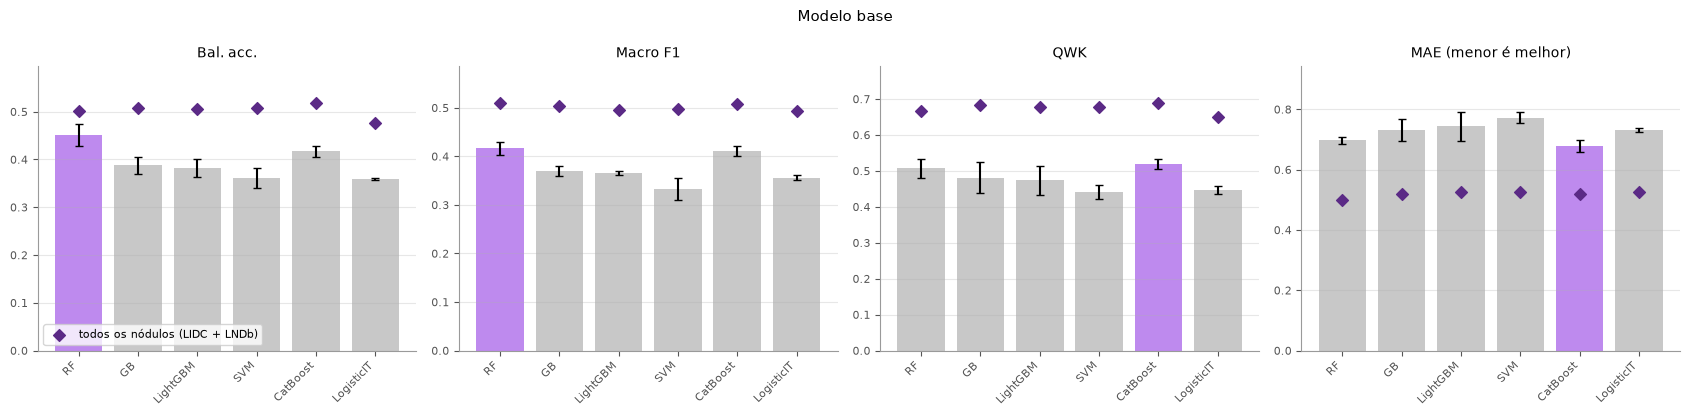

In [16]:
# 6.2 Modelo base: cada modelo com a configuração inicial
BASE = {m: correr(m) for m in MODELOS}
tabela_bonita(BASE)
grafico_barras(BASE, "Modelo base")

> **Diferença entre o LNDb e o conjunto completo.** Todos os modelos têm um desempenho bastante inferior nos nódulos do LNDb. O QWK em todos os nódulos varia entre 0,65 e 0,69, enquanto no LNDb fica entre 0,44 e 0,52. Os nódulos do LIDC são mais fáceis de prever e representam a maior parte dos dados, pelo que o desempenho global esconde as dificuldades no domínio do teste. A ordem dos modelos também muda entre os dois conjuntos: o RF e o CatBoost têm o maior QWK em todos os nódulos, sendo os dois modelos com melhor S score.

> **Comparação dos modelos.** Nenhum modelo é o melhor em todas as métricas. O **RF** tem o maior S (0.678) e o **CatBoost** tem os melhores QWK e MAE, com valores de 0,519 e 0,677 respetivamente. O **Random Forest** tem a melhor balanced accuracy (0,452) e o melhor macro F1 (0,417): acerta mais nas notas raras. O Gradient Boosting é também o mais instável (desvio de 0,105 no S).

> **Modelos mais fracos.** O **SVM** tem o S mais baixo (0,362), os piores valores de Macro F1 (0,333) e QWK (0,440), e dos piores valores balanced accuracy (0,361). Este resultado é esperado num modelo muito sensível aos hiperparâmetros e à escala das features, ainda com a configuração por defeito. O **LogisticIT** também fica abaixo (S de 0,428).

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.3 Pesos pela concordância entre radiologistas</div>

Nem todas as labels são igualmente fiáveis. Quando os radiologistas dão notas muito diferentes ao mesmo nódulo, a mediana é uma estimativa mais incerta da verdadeira malignidade do que quando todos concordam. Por isso, neste primeiro passo, testa-se se compensa dar mais importância no treino aos nódulos com maior concordância, usando os pesos calculados na secção 2.4. Cada modelo é avaliado com e sem estes pesos, que entram apenas no treino de cada fold, e a validação continua a ser feita sem pesos. Como `N_MELHORES` ≥ 2, as duas versões de cada modelo, com e sem pesos, passam ambas à 6.4, ordenadas por S (bal. acc. + macro F1 + QWK − MAE) no LNDb.

In [17]:
%%capture
# 6.3 Pesos pela concordância: cada modelo com e sem (sobre o modelo base). Com N_MELHORES ≥ 2,
#     as duas versões (com e sem pesos) passam ambas à 6.4
resultados = passo("pesos", lambda m: [False, True])

In [18]:
resumo_passo(resultados, escolhidas_atuais(), "Após os pesos (6.3)")

,Versão escolhida,Bal. acc.,Macro F1,QWK,MAE,S
RF,"pesos pela concordância, sem balanceamento, LNDb x1",0.453 ± 0.040,0.413 ± 0.022,0.523 ± 0.030,0.690 ± 0.026,0.699 ± 0.117
CatBoost,"sem pesos pela concordância, sem balanceamento, LNDb x1",0.418 ± 0.012,0.411 ± 0.011,0.519 ± 0.015,0.677 ± 0.020,0.670 ± 0.045
LightGBM,"pesos pela concordância, sem balanceamento, LNDb x1",0.387 ± 0.044,0.369 ± 0.043,0.508 ± 0.011,0.707 ± 0.007,0.556 ± 0.089
GB,"pesos pela concordância, sem balanceamento, LNDb x1",0.392 ± 0.044,0.366 ± 0.041,0.499 ± 0.031,0.727 ± 0.021,0.530 ± 0.128
LogisticIT,"sem pesos pela concordância, sem balanceamento, LNDb x1",0.359 ± 0.002,0.356 ± 0.005,0.446 ± 0.010,0.732 ± 0.007,0.428 ± 0.010
SVM,"pesos pela concordância, sem balanceamento, LNDb x1",0.363 ± 0.028,0.344 ± 0.023,0.443 ± 0.033,0.762 ± 0.021,0.387 ± 0.099


> Os pesos pela concordância melhoram muito atenuadamente quatro dos seis modelos: o **LightGBM**, o **Gradient Boosting**, o **Random Forest** e o **SVM**. O maior ganho é o do LightGBM, que melhora nas quatro métricas: a balanced accuracy sobe de 0,382 para 0,387, o macro F1 de 0,365 para 0,369, o QWK de 0,474 para 0,508 e o MAE desce de 0,744 para 0,707, com o S a passar de 0,477 para 0,556. No Gradient Boosting, no Random Forest e no SVM o ganho é menor (S +0,02 a +0,03), sobretudo no QWK e no MAE. Dar menos peso aos nódulos em que os radiologistas discordam reduz a influência das labels menos fiáveis, o que ajuda estes modelos a aproximar as previsões da nota correta.

> No **CatBoost** e na **regressão logística ordinal**, a melhor versão continua a ser a sem pesos, com os mesmos resultados do modelo base (6.2). O Random Forest continua a ser o melhor modelo até aqui (S de 0,699, com a melhor balanced accuracy, macro F1 e QWK), seguido de perto pelo CatBoost (S de 0,670 e melhor MAE).

> Estas diferenças são, no entanto, menores do que o desvio entre seeds (0,05 a 0,13 no S), pelo que devem ser lidas como tendências e não como melhorias garantidas. Por esse motivo, as duas versões de cada modelo (com e sem pesos) seguem para o passo seguinte.

> Os pesos não resolvem o problema das classes raras: a nota 4 continua a ser a mais difícil em todos os modelos, o que motiva o balanceamento das classes testado na 6.4a.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.4 (a) Balanceamento das classes</div>

As notas de malignidade estão muito desequilibradas: a maioria dos nódulos tem nota 2 ou 3, e as notas 4 e 5 são raras, sobretudo no LNDb. Sem nenhuma correção, os modelos tendem a prever quase sempre as classes frequentes, o que prejudica a balanced accuracy e o macro F1, que dão o mesmo peso a todas as classes. Neste passo testam-se três formas de compensar esse desequilíbrio, sobre as duas versões de cada modelo que saem da 6.3: não fazer nada, dar mais peso aos nódulos das classes raras (`"classe"`) ou duplicá-los (RandomOverSampler, `"ros"`). Nos classificadores (RF e regressão logística) testa-se também o SMOTE, que cria nódulos sintéticos por interpolação. Nos modelos de regressão esta opção não existe, porque os nódulos sintéticos não teriam uma nota contínua nem um paciente.

In [19]:
%%capture
# 6.4 (a) Balanceamento das classes: todas as opções possíveis, sobre cada uma das melhores versões da 6.3.
# O SMOTE só existe nos classificadores.
OPCOES_BAL = {m: [None, "classe", "ros"] + (["smote"] if M["tipo"] == "clf" else []) for m, M in MODELOS.items()}
resultados = passo("bal", lambda m: OPCOES_BAL[m])


In [20]:
resumo_passo(resultados, escolhidas_atuais(), "Após o balanceamento (6.4a)")

,Versão escolhida,Bal. acc.,Macro F1,QWK,MAE,S
RF,"sem pesos pela concordância, pesos de classe, LNDb x1",0.487 ± 0.028,0.466 ± 0.024,0.531 ± 0.016,0.656 ± 0.014,0.828 ± 0.064
CatBoost,"sem pesos pela concordância, sem balanceamento, LNDb x1",0.418 ± 0.012,0.411 ± 0.011,0.519 ± 0.015,0.677 ± 0.020,0.670 ± 0.045
GB,"pesos pela concordância, pesos de classe, LNDb x1",0.412 ± 0.024,0.393 ± 0.011,0.515 ± 0.036,0.703 ± 0.026,0.617 ± 0.092
LightGBM,"pesos pela concordância, RandomOverSampler, LNDb x1",0.407 ± 0.034,0.374 ± 0.028,0.504 ± 0.026,0.712 ± 0.030,0.572 ± 0.114
LogisticIT,"sem pesos pela concordância, RandomOverSampler, LNDb x1",0.412 ± 0.018,0.393 ± 0.020,0.471 ± 0.023,0.752 ± 0.046,0.524 ± 0.105
SVM,"pesos pela concordância, sem balanceamento, LNDb x1",0.363 ± 0.028,0.344 ± 0.023,0.443 ± 0.033,0.762 ± 0.021,0.387 ± 0.099


**Principais resultados:**

- **O balanceamento é o passo com maior efeito até aqui, mas não em todos os modelos.** Melhora quatro dos seis modelos face à melhor versão da 6.3, sobretudo na balanced accuracy e no macro F1, que dão o mesmo peso a todas as classes.
- **Random Forest** (pesos de classe, sem pesos pela concordância): é o maior ganho, com o S a passar de 0,699 para 0,828 e melhorias nas quatro métricas (balanced accuracy de 0,453 para 0,487, macro F1 de 0,413 para 0,466, QWK de 0,523 para 0,531 e MAE de 0,690 para 0,656). É o melhor modelo em todas as métricas.
- **Regressão logística** (RandomOverSampler): o S sobe de 0,428 para 0,524. A balanced accuracy sobe de 0,359 para 0,412 e o macro F1 de 0,356 para 0,393, mas o MAE piora ligeiramente (de 0,732 para 0,752).
- **Gradient Boosting** (pesos de classe, com pesos pela concordância): melhora nas quatro métricas, com o S a passar de 0,530 para 0,617.
- **LightGBM** (RandomOverSampler, com pesos pela concordância): ganho pequeno (S de 0,556 para 0,572), só na balanced accuracy e no macro F1; o QWK e o MAE ficam praticamente iguais.
- **CatBoost e SVM:** nenhum método de balanceamento os melhora, pelo que ficam sem balanceamento. O CatBoost continua a ser o segundo melhor modelo (S de 0,670) e o SVM o último (0,387).
- **Método escolhido:** os pesos de classe são os melhores no Random Forest e no Gradient Boosting, e o RandomOverSampler no LightGBM e na regressão logística. O SMOTE não é o melhor em nenhum modelo.

> **Incerteza:** os ganhos do Random Forest, da regressão logística e do Gradient Boosting (S +0,09 a +0,13) são da mesma ordem ou maiores do que o desvio entre seeds (0,06 a 0,11). Já o ganho do LightGBM (+0,02) fica bem abaixo desse desvio, e deve ser lido apenas como uma tendência.

> **Interação entre passos:** no Random Forest, os pesos pela concordância ajudavam sem balanceamento (6.3), mas a melhor versão com balanceamento é sem esses pesos. É por isso que cada passo mantém as duas melhores versões de cada modelo, e não apenas a melhor.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.4 (b) Peso dos nódulos do LNDb</div>

In [21]:
%%capture
# 6.4 (b) Peso dos nódulos do LNDb (1 a 4), sobre cada uma das melhores versões da 6.4a

PESOS_LNDB = [1, 2, 3, 4]
resultados = passo("peso_lndb", lambda m: PESOS_LNDB)

In [22]:
resumo_passo(resultados, escolhidas_atuais(), "Após o peso do LNDb (6.4b)")

,Versão escolhida,Bal. acc.,Macro F1,QWK,MAE,S
RF,"sem pesos pela concordância, pesos de classe, LNDb x4",0.485 ± 0.012,0.468 ± 0.011,0.552 ± 0.008,0.632 ± 0.019,0.874 ± 0.046
CatBoost,"sem pesos pela concordância, sem balanceamento, LNDb x1",0.418 ± 0.012,0.411 ± 0.011,0.519 ± 0.015,0.677 ± 0.020,0.670 ± 0.045
GB,"pesos pela concordância, sem balanceamento, LNDb x4",0.414 ± 0.053,0.391 ± 0.048,0.531 ± 0.037,0.676 ± 0.027,0.661 ± 0.121
LightGBM,"pesos pela concordância, sem balanceamento, LNDb x4",0.407 ± 0.029,0.395 ± 0.024,0.512 ± 0.034,0.688 ± 0.020,0.626 ± 0.088
LogisticIT,"sem pesos pela concordância, RandomOverSampler, LNDb x2",0.405 ± 0.026,0.391 ± 0.013,0.470 ± 0.006,0.741 ± 0.015,0.525 ± 0.030
SVM,"pesos pela concordância, sem balanceamento, LNDb x1",0.363 ± 0.028,0.344 ± 0.023,0.443 ± 0.033,0.762 ± 0.021,0.387 ± 0.099


**Principais resultados:**

- **Os três modelos de árvores (Random Forest, Gradient Boosting e LightGBM) beneficiam de dar mais peso ao LNDb**, e os três escolhem o peso máximo testado (×4).
- **Random Forest** (pesos de classe, LNDb ×4): o S sobe de 0,828 para 0,874, sobretudo no QWK (de 0,531 para 0,552) e no MAE (de 0,656 para 0,632), com a balanced accuracy e o macro F1 praticamente iguais. Continua a ser o melhor modelo em todas as métricas e passa a ser também dos mais estáveis entre seeds (desvio do S de 0,046).
- **Gradient Boosting** (LNDb ×4): o S sobe de 0,617 para 0,661. Com o LNDb a pesar ×4, deixa de precisar do balanceamento das classes e melhora o QWK (de 0,515 para 0,531) e o MAE (de 0,703 para 0,676).
- **LightGBM** (LNDb ×4): o S sobe de 0,572 para 0,626, e também deixa de usar o RandomOverSampler. Melhora o macro F1, o QWK e o MAE, com a balanced accuracy igual.
- **Regressão logística** (LNDb ×2): os resultados ficam praticamente iguais (S de 0,524 para 0,525).
- **CatBoost e SVM ficam com o peso ×1:** pesos maiores não os melhoram.

> **Interpretação.** Dar mais peso aos nódulos do LNDb aproxima o treino do domínio do teste. Nos modelos de árvores, isto melhora o desempenho no LNDb, e no Gradient Boosting e no LightGBM chega a substituir o balanceamento das classes: como no LNDb as notas 1 e 2 são mais frequentes do que no LIDC, dar-lhe mais peso também altera a distribuição das notas que o modelo vê no treino. Os ganhos (S +0,04 a +0,05) são, no entanto, menores do que o desvio entre seeds (0,05 a 0,12). Além disso, o melhor peso é o máximo testado (×4), pelo que não se sabe se pesos maiores ajudariam ainda mais.

> **Até que ponto é aceitável gerar dados artificiais num problema clínico?** O SMOTE não cria imagens nem pacientes. Cria pontos sintéticos no espaço das features, por interpolação entre nódulos vizinhos da mesma classe rara. Aqui, esses pontos entram apenas no treino, e todas as métricas são calculadas em nódulos reais. Mesmo assim, um ponto interpolado não corresponde necessariamente a um nódulo plausível, sobretudo com centenas de features, onde o SMOTE tende a trazer pouco benefício. Além disso, as correções do desequilíbrio levam os modelos a sobrestimar o risco das classes raras, sem melhorarem a distinção entre casos [1, 2], o que, na prática clínica, pode traduzir-se em exames desnecessários. O SMOTE justifica-se, por isso, para otimizar as métricas desta competição. Num modelo para uso clínico, seria preferível ajustar os limiares de decisão, como no notebook 3, e avaliar a calibração das previsões.

**Referências**

[1] van den Goorbergh, R., van Smeden, M., Timmerman, D., & Van Calster, B. (2022). The harm of class imbalance corrections for risk prediction models: illustration and simulation using logistic regression. *Journal of the American Medical Informatics Association*, 29(9), 1525–1534. https://doi.org/10.1093/jamia/ocac093

[2] Carriero, A., Luijken, K., de Hond, A., Moons, K. G. M., van Calster, B., & van Smeden, M. (2025). The harms of class imbalance corrections for machine learning based prediction models: a simulation study. *Statistics in Medicine*, 44(3–4), e10320. https://doi.org/10.1002/sim.10320

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.5 Hiperparâmetros</div>

Até aqui, os modelos usaram os hiperparâmetros iniciais da 6.1. Neste passo, as duas melhores versões de cada modelo são afinadas com uma pesquisa aleatória (`ParameterSampler`), que testa um número fixo de combinações escolhidas ao acaso. Por limitações de tempo, testaram-se 20 combinações no Random Forest (com 3 seeds) e no Gradient Boosting (com 1 seed), e 8 nos restantes modelos (com 1 seed). Fica a combinação com maior S (bal. acc. + macro F1 + QWK − MAE) nos modelos. Como a melhor de várias tentativas tende a ser otimista, cada versão afinada é no fim comparada, com as 3 seeds, com a versão inicial, e fica a melhor.

In [23]:
%%capture
# 6.5 Hiperparâmetros: grelha de cada modelo (pesquisa aleatória: 20 combinações no RF; 8 nos restantes, por
#     limitações de tempo)


GRELHAS = {
    "RF": {"n_estimators": [200, 300, 500, 700], "max_depth": [None, 5, 10, 15, 20], "min_samples_split": [2, 5, 10],
           "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2", None]},
    "GB": {"learning_rate": [0.02, 0.05, 0.08, 0.1], "max_iter": [200, 300, 500], "max_leaf_nodes": [7, 15, 31],
           "min_samples_leaf": [10, 20, 30], "l2_regularization": [0.0, 1.0, 5.0]},
    "LightGBM": {"n_estimators": [100, 200, 300, 500], "learning_rate": [0.02, 0.05, 0.1], "num_leaves": [7, 15, 31],
                 "min_child_samples": [10, 20, 30], "reg_lambda": [0.0, 1.0, 5.0], "colsample_bytree": [0.5, 0.8, 1.0]},
    "SVM": {"C": [0.1, 0.5, 1, 2, 5, 10, 20, 50, 100], "gamma": ["scale", 0.001, 0.005, 0.01, 0.05, 0.1],
            "epsilon": [0.01, 0.05, 0.1, 0.2, 0.3]},
    "CatBoost": {"learning_rate": [0.03, 0.05, 0.1], "iterations": [200, 400, 600], "depth": [3, 4, 6],
                 "l2_leaf_reg": [1.0, 3.0, 5.0, 10.0], "rsm": [0.5, 0.8, 1.0]},
    "LogisticIT": {"alpha": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
}
# Nome do ficheiro da cache de cada pesquisa: inclui a versão afinada (se mudar, a pesquisa repete-se)
def nome_cache(m, c):
    return f"{m.lower()}_{ASSINATURA}_bal{c['bal']}_peso{c['peso_lndb']}{'_conc' if c['pesos'] else ''}"


# Cada uma das melhores versões de cada modelo é afinada; no fim fica a melhor entre as versões afinadas e
# as não afinadas (a pesquisa nem sempre melhora), comparadas todas com as mesmas 3 seeds
resultados = {}
for m, grelha in GRELHAS.items():
    finalistas = []
    for i, c in enumerate(CANDIDATOS[m], start=1):
        print(f"\n{m}, versão {i} ({descrever(c)}):")
        # criar_cfg(p, s): esta versão com os hiperparâmetros p a testar
        criar_cfg = lambda p, s, m=m, c=c: montar(m, {**c, "params": {**c["params"], **p}})(s)
        # Por limitações de tempo: o RF com a pesquisa completa (20 combinações, 3 seeds); os restantes com
        # 8 combinações e 1 seed. As combinações já guardadas das em cache_tuning/ são sempre reaproveitadas.
        n_comb = 20 if m == "RF" else 8
        melhor = pesquisa(nome_cache(m, c), criar_cfg, grelha, seeds=SEEDS if m == "RF" else SEEDS[:1],
                          criterio="score",
                          n_iter=min(n_comb, np.prod([len(v) for v in grelha.values()])))
        afinada = {**c, "params": {**c["params"], **melhor}}
        resultados[(m, descrever(c))] = correr_cfg(m, c)                    # (já em cache)
        resultados[(m, descrever(c) + " | afinada")] = correr_cfg(m, afinada)
        finalistas += [c, afinada]
    CONFIG[m] = max(finalistas, key=lambda c: SCORE[(m, repr(c))])         # a melhor de todas
    CANDIDATOS[m] = [CONFIG[m]]
print("Versão final de cada modelo:", {m: descrever(c) + (" | afinada" if c["params"] != MODELOS[m]["params"] else "")
                                      for m, c in CONFIG.items()})

In [24]:
tabela_bonita(resultados)
resumo_passo(resultados, escolhidas_atuais(com_afinacao=True), "Versão final de cada modelo (6.5)")

,Versão escolhida,Bal. acc.,Macro F1,QWK,MAE,S
RF,"sem pesos pela concordância, pesos de classe, LNDb x4",0.485 ± 0.012,0.468 ± 0.011,0.552 ± 0.008,0.632 ± 0.019,0.874 ± 0.046
LogisticIT,"sem pesos pela concordância, RandomOverSampler, LNDb x1, hiperparâmetros da pesquisa",0.458 ± 0.033,0.433 ± 0.027,0.516 ± 0.018,0.677 ± 0.023,0.730 ± 0.101
LightGBM,"pesos pela concordância, sem balanceamento, LNDb x3, hiperparâmetros da pesquisa",0.423 ± 0.022,0.404 ± 0.024,0.541 ± 0.039,0.657 ± 0.046,0.710 ± 0.124
CatBoost,"sem pesos pela concordância, sem balanceamento, LNDb x1",0.418 ± 0.012,0.411 ± 0.011,0.519 ± 0.015,0.677 ± 0.020,0.670 ± 0.045
GB,"pesos pela concordância, sem balanceamento, LNDb x4",0.414 ± 0.053,0.391 ± 0.048,0.531 ± 0.037,0.676 ± 0.027,0.661 ± 0.121
SVM,"pesos pela concordância, sem balanceamento, LNDb x2, hiperparâmetros da pesquisa",0.405 ± 0.043,0.391 ± 0.030,0.482 ± 0.030,0.699 ± 0.014,0.579 ± 0.115


> **A afinação é decisiva nos modelos mais sensíveis aos hiperparâmetros.** A **regressão logística** é a que mais beneficia: o S passa de 0,524 para 0,730, com melhorias nas quatro métricas (balanced accuracy de 0,412 para 0,458, macro F1 de 0,393 para 0,433, QWK de 0,471 para 0,516 e MAE de 0,752 para 0,677). O **SVM** também melhora muito, com o S a passar de 0,387 para 0,579 (QWK de 0,443 para 0,482 e MAE de 0,762 para 0,699). O **LightGBM** melhora de forma mais moderada (S de 0,626 para 0,710, QWK de 0,512 para 0,541 e MAE de 0,688 para 0,657) e passa a ter o melhor QWK em todos os nódulos (0,697).

> **No Random Forest, no CatBoost e no Gradient Boosting ficam os hiperparâmetros iniciais**, porque a pesquisa não encontrou nenhuma combinação melhor: as versões afinadas têm um S igual ou inferior (no Random Forest, 0,813 contra 0,874). O Random Forest continua a ser o melhor modelo nas quatro métricas (S de 0,874), seguido da regressão logística (0,730) e do LightGBM (0,710).

> **A segunda versão de cada modelo também conta.** Na regressão logística e no LightGBM, a versão final vem da segunda melhor versão da 6.4b (LNDb ×1 e ×3, respetivamente), e não da melhor: depois de afinada, ultrapassa a versão que estava à frente. É um exemplo de porque se mantêm as duas melhores versões em cada passo.

> **A pesquisa é otimista:** a melhor de várias combinações beneficia, em parte, de sorte nessa divisão dos dados. Por isso, cada versão afinada é reavaliada com as 3 seeds e comparada com a versão inicial antes da decisão final. Os ganhos são, ainda assim, em vários casos menores do que o desvio entre seeds (0,05 a 0,12 no S).

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.6 Seleção de features</div>

Até aqui, todos os modelos foram treinados com as cerca de 300 features que sobram da seleção da 5.1, que retira as features quase constantes e as redundantes. Reduzir as features costuma ajudar quando há poucos nódulos, porque diminui o ruído e o risco de sobreajuste. No entanto, também pode deitar fora informação útil. Neste passo, cada modelo, já com a sua configuração final, é avaliado com e sem essa seleção. A versão sem seleção usa as 1130 features, apenas com imputação e normalização.

In [25]:
# 6.6 Seleção de features: cada modelo com e sem a seleção da 5.1 (seed_modelo=True: a seed de cada repetição)
resultados = {}
for m in MODELOS:
    resultados[(m, "com seleção")] = correr(m, seed_modelo=True)
    resultados[(m, "sem seleção")] = correr(m, seed_modelo=True, selecao=False)
tabela_bonita(resultados)

A tabela compara a versão final de cada modelo com e sem a seleção de features da 5.1 (cerca de 300 das 1130 features).

- **A seleção melhora bastante o SVM** (S de 0,257 para 0,579, QWK de 0,411 para 0,482 e MAE de 0,795 para 0,699): o kernel RBF mede distâncias entre nódulos usando todas as features, e sem seleção essas distâncias são dominadas por grupos de features redundantes.
- **Melhora também o Random Forest, o LightGBM e o CatBoost nas quatro métricas** (S de 0,731 para 0,844, de 0,659 para 0,743 e de 0,535 para 0,610, respetivamente).
- **Na regressão logística, o efeito é misto:** a seleção melhora a balanced accuracy e o macro F1 (de 0,438 para 0,458 e de 0,423 para 0,433), mas o QWK e o MAE ficam ligeiramente melhores sem seleção.
- **No Gradient Boosting, a versão sem seleção é ligeiramente melhor** (S de 0,681 contra 0,661) e mais estável entre seeds, mas as diferenças são de 0,01 ou menos em cada métrica, bem abaixo do desvio entre seeds (0,12 no S).

A seleção é mantida em todos os modelos: ajuda claramente em quatro deles, as diferenças nos outros dois são pequenas, e reduz as features para menos de um terço.

Neste passo, cada repetição usa uma seed diferente no modelo, e não sempre a mesma. Por isso, nos modelos com aleatoriedade interna (Random Forest, LightGBM e CatBoost), os valores "com seleção" diferem ligeiramente dos da 6.5.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.7 Reavaliação com outras seeds (42, 123, 2024)</div>

Ao longo dos passos anteriores, cada modelo foi escolhido entre muitas configurações, sempre avaliadas nas mesmas divisões em folds (seeds 42, 7 e 123). Quando se escolhe a melhor de muitas tentativas nos mesmos dados, parte da vantagem vem do acaso: a configuração vencedora tende a ser a que se ajustou melhor àquelas divisões em particular, e o seu resultado é otimista. Para obter uma estimativa mais justa, a configuração final de cada modelo é reavaliada com outras divisões em folds (seeds 42, 123 e 2024), agora também com uma seed diferente no modelo em cada repetição. Como só a seed 2024 é inteiramente nova, esta correção é apenas parcial, mas é esta a estimativa usada para comparar os modelos na 6.9.

Para cada modelo apresenta-se uma tabela com as quatro métricas no LNDb (média ± desvio entre seeds) e em todos os nódulos (LIDC + LNDb), o recall de cada nota no LNDb e um gráfico em que as barras são as métricas no LNDb, com o desvio entre seeds, e os losangos são as métricas em todos os nódulos.

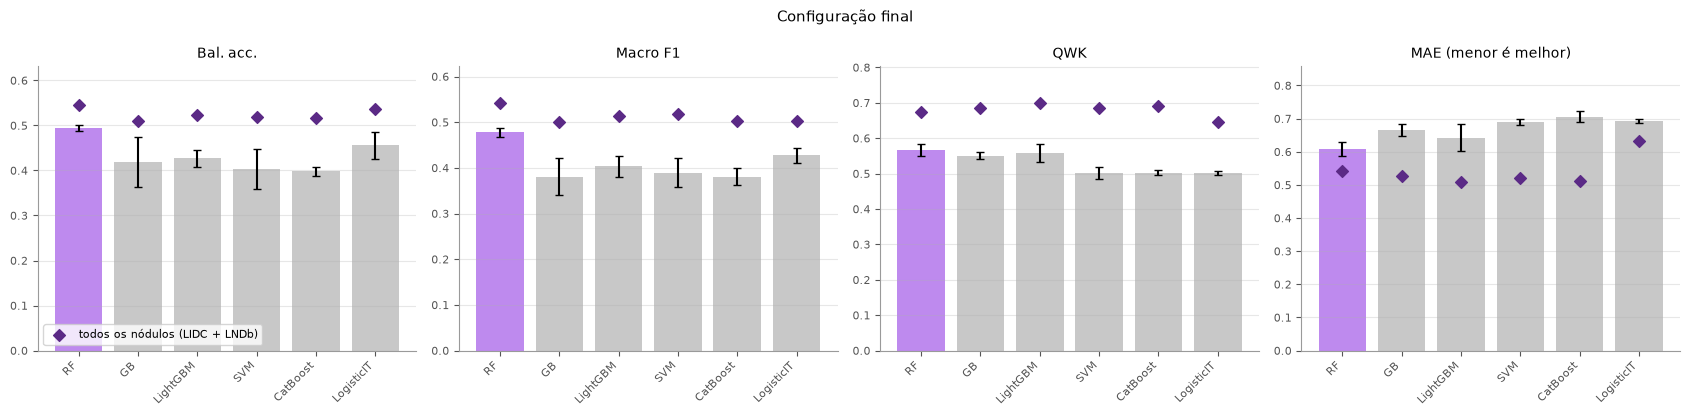

In [26]:
# 6.7 Reavaliação: a configuração final de cada modelo com 3 seeds novas (as anteriores foram usadas nas escolhas)
FINAIS = {m: correr(m, seeds=SEEDS_REAVALIACAO, seed_modelo=True) for m in MODELOS}
tabela_bonita(FINAIS, recall=True, todos_nodulos=True)
grafico_barras(FINAIS, "Configuração final")

> **No LNDb, o Random Forest é o melhor modelo nas quatro métricas** (balanced accuracy 0,494, macro F1 0,478, QWK 0,567 e MAE 0,608), com o maior S (0,931) e desvios entre seeds pequenos (0,007 a 0,021 em cada métrica). Segue-se o LightGBM (S de 0,746), com o segundo melhor QWK (0,559) e MAE (0,642). A distância entre o Random Forest e os restantes (S de 0,575 a 0,746) é maior do que o desvio entre seeds (0,05 a 0,12), o que torna esta vantagem mais segura do que nos passos anteriores.

> **Em todos os nódulos (LIDC + LNDb), os modelos ficam muito próximos** (QWK entre 0,65 e 0,70). O Random Forest continua a ter a melhor balanced accuracy (0,546) e o melhor macro F1 (0,542), mas o LightGBM passa a ter o melhor QWK (0,699) e o melhor MAE (0,509). As diferenças entre modelos aparecem sobretudo no LNDb, o domínio do teste, onde o Random Forest beneficia do peso ×4 dos nódulos do LNDb e dos pesos de classe.

> **Recall por nota no LNDb:** há uma troca entre as notas raras e a nota 3. O Random Forest e a regressão logística, os dois modelos com balanceamento, são os que melhor reconhecem as notas 4 e 5 (Random Forest: 0,29 e 0,75; regressão logística: 0,16 e 0,71), mas acertam pouco na nota 3 (0,22 e 0,32). Nos modelos sem balanceamento (LightGBM, Gradient Boosting, SVM e CatBoost), a nota 3 é bem reconhecida (0,45 a 0,53), mas a nota 4 quase nunca é prevista (0,03 a 0,11). A nota 4 é a mais difícil em todos os modelos, por ter muito poucos nódulos no LNDb.

A comparação entre modelos com intervalos de confiança é feita na 6.9.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.8 Modelos finais</div>

Cada modelo, com a sua configuração final, é treinado com todos os nódulos exceto os do holdout e usado para prever o holdout. As previsões ficam guardadas em resultados/, juntamente com as previsões out-of-fold da 6.7, para serem comparadas na 6.9.

In [27]:
%%capture

# 6.8 Modelos finais: cada um treinado e guardado em resultados/ (com o nome usado na 6.9)

NOME_FINAL = {"RF": "RF otimizado", "GB": "GB otimizado", "LightGBM": "LGBM otimizado", "SVM": "SVM otimizado",
              "CatBoost": "CatBoost otimizado", "LogisticIT": "LogisticIT"}


def modelo_final(nome, pop):
    """O modelo com a configuração final, para a população de treino 'pop' (POP_DEV ou POP_TUDO)."""
    # As mesmas classes da validação cruzada: os pesos e o balanceamento são aplicados exatamente da mesma forma
    M, cfg = MODELOS[nome], CONFIG[nome]
    w = pesos_cfg(pop, cfg)
    if M["tipo"] == "clf":
        return Classificador(M["novo"](cfg["params"], 42), w, cfg["bal"])
    return RegressaoBalanceada(M["novo"](cfg["params"], 42), pop.alvo, pop.grupos, w, cfg["bal"])


for m in MODELOS:
    finalizar_modelo(NOME_FINAL[m], lambda pop, m=m: modelo_final(m, pop), FINAIS[m][1],
                     descricao=str(CONFIG[m]), teste=False)

In [28]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):          # esconde os avisos da carregar_todos
    todos_res = carregar_todos()
mostrar(tabela_metricas({m: metr(df_holdout["classe"].to_numpy(), todos_res[NOME_FINAL[m]]["pred_holdout"])
                         for m in MODELOS}, "Holdout"))

,Bal. acc.,Macro F1,QWK,MAE
RF,0.350,0.373,0.395,0.722
GB,0.389,0.388,0.370,0.722
LightGBM,0.343,0.347,0.353,0.792
SVM,0.333,0.329,0.400,0.736
CatBoost,0.365,0.350,0.403,0.764
LogisticIT,0.438,0.411,0.428,0.708


> **O holdout não confirma a ordem da validação cruzada.** A regressão logística ordinal, que estava a meio da tabela na 6.7, é a melhor no holdout nas quatro métricas (balanced accuracy 0,438, macro F1 0,411, QWK 0,428 e MAE 0,708). O Random Forest, o melhor na validação cruzada, fica a meio, com um QWK de 0,395 e um MAE de 0,722. Todos os modelos ficam abaixo dos valores da validação cruzada: no Random Forest, o QWK passa de 0,567 (6.7) para 0,395. Parte desta diferença é otimismo da validação cruzada, porque as configurações foram escolhidas entre muitas alternativas com os mesmos dados. Um modelo mais simples, como a regressão logística, tende a sofrer menos com este efeito.

> **O holdout é pequeno para ordenar os modelos.** Tem apenas 72 nódulos, com poucos das notas 4 e 5, pelo que um ou dois nódulos classificados de forma diferente mudam visivelmente as métricas, sobretudo a balanced accuracy e o macro F1, que dão o mesmo peso às cinco notas. As diferenças entre modelos devem, por isso, ser lidas com os intervalos de confiança da 6.9, e a validação cruzada, com mais nódulos, continua a ser a referência principal.

**Ensemble de especialistas por classe.** Os modelos têm perfis diferentes por nota (6.7): o Random Forest é o que melhor reconhece as notas 4 e 5, e o Gradient Boosting, o CatBoost e o LightGBM os que melhor reconhecem a nota 3. Por isso, é acrescentada à comparação da 6.9 um ensemble em que **cada nota é entregue ao modelo que melhor a prevê**:

- **Escolha do especialista:** para cada nota, o modelo com o melhor F1 nessa nota, nas previsões *out-of-fold* do LNDb. Usa-se o F1 e não o recall, porque o recall favoreceria modelos que preveem uma nota em excesso. Os especialistas escolhidos são: RF nas notas 1, 2, 4 e 5 e LightGBM na nota 3.
- **Combinação:** cada especialista "reclama" os nódulos em que prevê a sua nota. Em caso de conflito, ganha a nota cujo especialista tem maior precisão. Se nenhum reclamar, fica a previsão do Random Forest, o melhor modelo da 6.7.
- **Avaliação sem enviesamento:** na estimativa *out-of-fold*, os especialistas de cada fold são escolhidos só com os pacientes de fora desse fold. Para o holdout e para o teste, são escolhidos com todos os nódulos do LNDb fora do holdout.

In [29]:
%%capture saida_esp
# 6.9a Ensemble de especialistas por classe: para cada nota, o modelo com melhor F1 nessa nota no LNDb.
#      Usa só as previsões já gravadas em resultados/ (não treina nada) e é guardado como mais um modelo.
import comum as C
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, precision_score

NOME_ESP = "Especialistas por classe"
BASE_ESP = "RF otimizado" # usado nos nódulos que nenhum especialista reclama
MODELOS_ESP = list(NOME_FINAL.values()) # candidatos a especialista: os seis modelos finais

res_esp = {n: r for n, r in C.carregar_todos().items() if n in MODELOS_ESP}
y_l, pac_l = C.y.to_numpy()[C.e_lndb], C.grupos.to_numpy()[C.e_lndb]          # labels e pacientes do LNDb
seeds_esp = [s for s in res_esp[BASE_ESP]["oof"].columns if all(s in r["oof"].columns for r in res_esp.values())]
pred_l_esp = {n: [r["oof"][s].to_numpy()[C.e_lndb] for s in seeds_esp] for n, r in res_esp.items()}


def escolher_especialistas(idx):
    """Por nota: o modelo com melhor F1 nessa nota nos nódulos idx (média das seeds) e a precisão desse modelo."""
    esp, prec = {}, {}
    for c in C.CLASSES:
        f1 = {m: np.mean([f1_score(y_l[idx] == c, p[idx] == c, zero_division=0) for p in pred_l_esp[m]])
              for m in MODELOS_ESP}
        esp[c] = max(f1, key=f1.get)
        prec[c] = np.mean([precision_score(y_l[idx] == c, p[idx] == c, zero_division=0) for p in pred_l_esp[esp[c]]])
    return esp, prec


def combinar_especialistas(pred, esp, prec):
    """Cada especialista 'reclama' os nódulos em que prevê a sua nota. Em caso de conflito, ganha a nota cujo
    especialista é mais preciso; se nenhum reclama, fica a previsão do modelo base."""
    out = np.array(pred[BASE_ESP]).copy()
    reclamam = np.array([np.asarray(pred[esp[c]]) == c for c in C.CLASSES]).T
    for i in np.where(reclamam.any(axis=1))[0]:
        out[i] = max([c for k, c in enumerate(C.CLASSES) if reclamam[i, k]], key=lambda c: prec[c])
    return out


# Estimativa out-of-fold: em cada fold, os especialistas são escolhidos só com os pacientes de fora desse fold
oof_esp = [np.zeros(len(y_l), dtype=int) for _ in seeds_esp]
for tr, te in GroupKFold(n_splits=5).split(y_l, groups=pac_l):
    esp_f, prec_f = escolher_especialistas(tr)
    for k in range(len(seeds_esp)):
        oof_esp[k][te] = combinar_especialistas({m: pred_l_esp[m][k][te] for m in MODELOS_ESP}, esp_f, prec_f)

# Modelo final: especialistas escolhidos com todos os nódulos do LNDb fora do holdout
ESP, PREC_ESP = escolher_especialistas(np.arange(len(y_l)))
print("Especialista de cada nota:")
for c in C.CLASSES:
    print(f"  nota {c}: {ESP[c]} (precisão {PREC_ESP[c]:.2f})")

# Guarda como mais um modelo em resultados/ (as linhas do LIDC ficam com o modelo base; só o LNDb é usado)
oof_df = res_esp[BASE_ESP]["oof"][seeds_esp].copy()
for k, s in enumerate(seeds_esp):
    col = oof_df[s].to_numpy().copy()
    col[C.e_lndb] = oof_esp[k]
    oof_df[s] = col
pd.to_pickle({"nome": NOME_ESP, "assinatura": C.ASSINATURA, "oof": oof_df,
              "pred_holdout": combinar_especialistas({m: res_esp[m]["pred_holdout"] for m in MODELOS_ESP}, ESP, PREC_ESP),
                            "pred_teste": None,
              "descricao": f"especialistas {ESP}"}, C._caminho(NOME_ESP))
print(f"{NOME_ESP} guardado em resultados/")

In [30]:
print("\n".join(l for l in saida_esp.stdout.splitlines() if not l.startswith("Aviso")))

Especialista de cada nota:
  nota 1: RF otimizado (precisão 0.68)
  nota 2: RF otimizado (precisão 0.46)
  nota 3: LGBM otimizado (precisão 0.34)
  nota 4: RF otimizado (precisão 0.42)
  nota 5: RF otimizado (precisão 0.53)
Especialistas por classe guardado em resultados/


<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">6.9 Comparação dos modelos clássicos</div>

Os seis modelos finais, três ensembles (média das notas dos membros, arredondada) e o ensemble de especialistas são comparados no LNDb, com intervalos de confiança de 95% obtidos por bootstrap de 500 amostras **por paciente**.

**Regra de decisão:** é escolhido o modelo com o menor rank médio nas quatro métricas no LNDb (*out-of-fold*), o mesmo critério do leaderboard da competição; em caso de empate, o de maior QWK. Os intervalos de confiança servem para avaliar se as diferenças entre modelos são distinguíveis.

São apresentados: a tabela com os valores no LNDb (com intervalo de confiança) e no holdout; um gráfico com os mesmos valores; a matriz de confusão do modelo escolhido; e a a distribuição das notas previstas no holdout, comparada com a do LIDC e do LNDb.

In [31]:
%%capture saida
# 6.9 Comparação dos seis modelos clássicos e de três ensembles (função em comum.py)
CANDIDATOS_6_9 = list(NOME_FINAL.values()) + ["Especialistas por classe"]
CONJUNTOS_CLASSICOS = {
    "Ensemble árvores": ["GB otimizado", "LGBM otimizado", "CatBoost otimizado"],
    "Ensemble árvores + SVM": ["GB otimizado", "LGBM otimizado", "CatBoost otimizado", "SVM otimizado"],
    "Ensemble dos 5 modelos": ["RF otimizado", "GB otimizado", "LGBM otimizado", "CatBoost otimizado", "SVM otimizado"]}
ESCOLHA_CLASSICOS = comparar_modelos(CANDIDATOS_6_9, conjuntos=CONJUNTOS_CLASSICOS, mostrar=False)


Rank médio no LNDb (menor é melhor): RF otimizado 1.00 | Especialistas por classe 2.00 | Ensemble dos 5 modelos 3.75 | LGBM otimizado 4.25 | LogisticIT 6.00 | GB otimizado 6.50 | Ensemble árvores + SVM 6.50 | Ensemble árvores 7.25 | SVM otimizado 8.50 | CatBoost otimizado 9.25 | ESCOLHIDO: RF otimizado


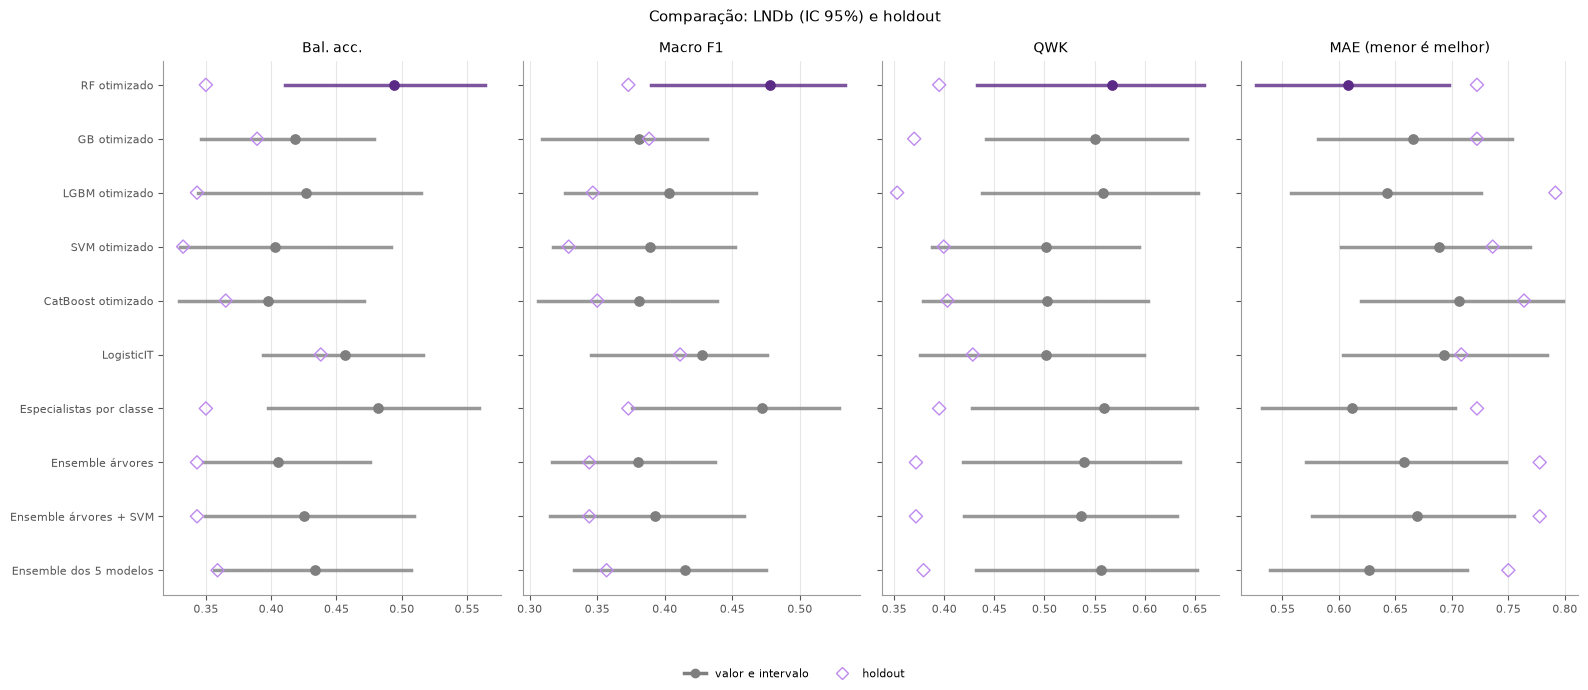

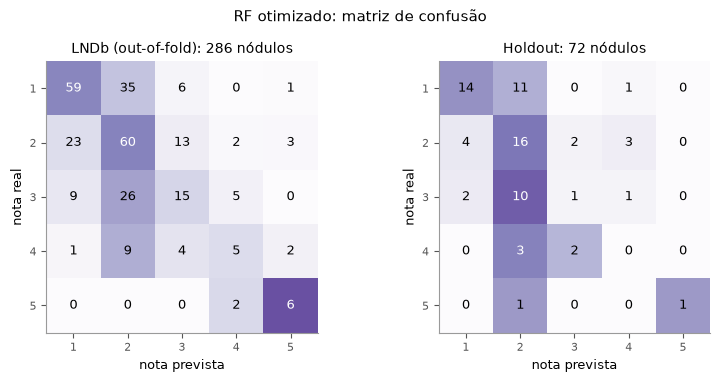

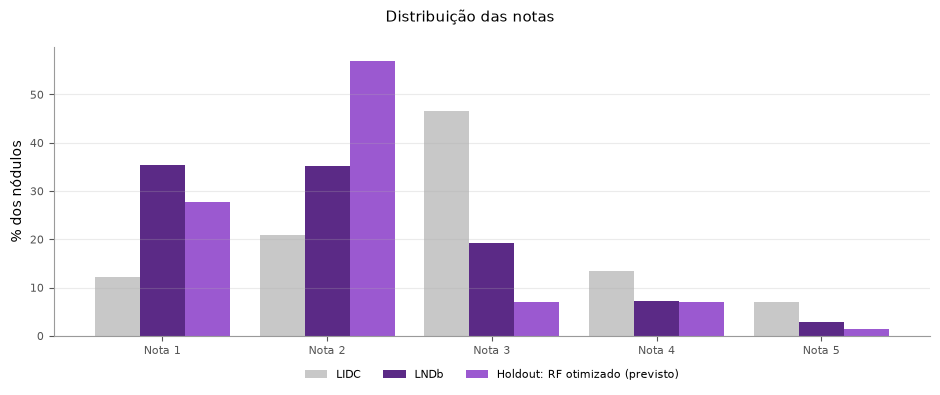

In [33]:
import contextlib, io
print(next(l for l in saida.stdout.splitlines() if l.startswith("Rank médio")))
with contextlib.redirect_stdout(io.StringIO()):          # esconde só os avisos
    tabela_comparacao(CANDIDATOS_6_9, CONJUNTOS_CLASSICOS, escolhido=ESCOLHA_CLASSICOS)
    grafico_comparacao(CANDIDATOS_6_9, CONJUNTOS_CLASSICOS)
    matrizes_confusao(ESCOLHA_CLASSICOS)
    distribuicao_notas({f"Holdout: {ESCOLHA_CLASSICOS} (previsto)":
                        dados_comparacao(CANDIDATOS_6_9, CONJUNTOS_CLASSICOS)["hold"][ESCOLHA_CLASSICOS]})

> **Resultado:** o modelo escolhido é o **Random Forest**, o melhor nas quatro métricas no LNDb (balanced accuracy 0,494, macro F1 0,478, QWK 0,567 e MAE 0,608) e, por isso, com o menor rank médio possível e o maior S (0,931). Em segundo lugar fica o ensemble de especialistas por classe (S de 0,902), que é quase igual ao Random Forest: no holdout, os dois têm exatamente os mesmos valores. Os ensembles por média das notas ficam abaixo do Random Forest em todas as métricas.

> **Os intervalos de confiança sobrepõem-se bastante:** no LNDb, o QWK de todos os modelos fica entre cerca de 0,38 e 0,66, porque há apenas 286 nódulos do LNDb fora do holdout. A ordem dos modelos é, por isso, pouco segura, embora o Random Forest seja o melhor nas quatro métricas.

> **No holdout**, o Random Forest fica abaixo da validação cruzada (QWK de 0,395 e MAE de 0,722) e não é o melhor modelo: a regressão logística é a melhor nas quatro métricas. Com 72 nódulos e poucos das notas 4 e 5, estas diferenças são pouco fiáveis, mas mostram que a estimativa da validação cruzada é otimista.

> **Matriz de confusão:** a maior parte dos erros é entre notas vizinhas, o que explica um QWK razoável apesar da balanced accuracy modesta. No LNDb, a nota 5 é bem reconhecida (6 de 8 nódulos), mas a nota 4 só é acertada em 5 de 21. No holdout, o modelo tende a prever a nota 2: 10 dos 14 nódulos de nota 3 e 3 dos 5 de nota 4 são classificados como nota 2, e nenhum nódulo de nota 4 é acertado.

> **Distribuição das notas no holdout:** o modelo prevê demasiadas notas 2 (57%, contra 35% no LNDb) e poucas notas 3 (7%, contra 19%). As notas 4 e 5 aparecem em proporções próximas das do LNDb.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">Conclusões (modelos clássicos)</div>
<br>

Ao longo da secção 6, os passos com maior efeito foram o balanceamento das classes e a afinação de hiperparâmetros. O balanceamento melhorou sobretudo o Random Forest, a regressão logística e o Gradient Boosting, com os pesos de classe a funcionar melhor nos dois modelos de árvores e o RandomOverSampler na regressão logística. A afinação foi decisiva nos modelos mais sensíveis aos hiperparâmetros, a regressão logística e o SVM, e ajudou também o LightGBM. O peso dos nódulos do LNDb beneficiou os três modelos de árvores, todos com o peso máximo testado (×4), e a seleção de features ajudou claramente o SVM, o Random Forest, o LightGBM e o CatBoost. Os pesos pela concordância entre radiologistas tiveram efeitos pequenos.

O modelo escolhido é o **Random Forest**, com pesos de classe, peso ×4 para o LNDb e os hiperparâmetros iniciais. É o melhor nas quatro métricas no LNDb (balanced accuracy 0,494, macro F1 0,478, QWK 0,567 e MAE 0,608) e, por isso, o de menor rank médio. Nem os ensembles por média das notas nem o ensemble de especialistas por classe o superaram, e este último fica muito próximo dele. Ainda assim, os intervalos de confiança de todos os modelos sobrepõem-se bastante (QWK entre cerca de 0,38 e 0,66), pelo que a vantagem do Random Forest, embora consistente nas quatro métricas, é pouco segura.

No **holdout**, o desempenho é inferior ao da validação cruzada (QWK de 0,395 no Random Forest), o que reflete o otimismo acumulado pelas muitas escolhas feitas com os mesmos dados. A ordem dos modelos também muda, com a regressão logística à frente nas quatro métricas, mas, com apenas 72 nódulos, estas diferenças são pouco fiáveis. Quanto aos erros, a maior parte ocorre entre notas vizinhas: a nota 4 é a mais difícil em todos os modelos, e no holdout o modelo tende a classificar as notas 3 e 4 como nota 2.

Este trabalho tem algumas **limitações**. O LNDb tem poucos nódulos (286 fora do holdout e 72 no holdout), sobretudo das notas 4 e 5, o que torna as estimativas instáveis. Existe também uma diferença de domínio (*domain shift*) entre o LIDC e o LNDb. O melhor peso do LNDb ficou no limite da grelha testada (×4), e a pesquisa de hiperparâmetros foi reduzida em alguns modelos por limitações de tempo. Além disso, a regra de escolha da 6.9 e o ensemble de especialistas foram definidos depois de vistos os primeiros resultados da comparação. Por fim, a label usada é a mediana das notas dos radiologistas, enquanto a competição usa a média, o que é corrigido na segunda versão do trabalho (notebook 3).